## **HRRR Data Integration**


### **Required Libraries**

In [1]:

import pandas as pd, numpy as np, matplotlib.pyplot as plt
from matplotlib.colors import BoundaryNorm
from pathlib import Path
from datetime import datetime, date, timezone, timedelta
import requests
import random
from tqdm import tqdm
import re

import cartopy.crs as ccrs
import cartopy.feature as cfeature

from eccodes import (
    codes_get,
    codes_get_array,
    codes_grib_new_from_file,
    codes_release,
    )



### **Root Paths**

In [2]:

root_path = Path.cwd()
data_path = root_path / 'data'
data_path.mkdir(exist_ok=True)

mrms_pth = root_path / 'data/mrms/radar_only_qpe/2023/06/28/'
print(data_path.exists(), mrms_pth.exists())


True True


### **Utils**

In [3]:


# a function to download a single file
def download_file(url, destination, chunk_size=8 * 1024 * 1024):
    """Download a file with size verification and tqdm progress."""

    destination = Path(destination)
    destination.parent.mkdir(parents=True, exist_ok=True)

    temporary_path = destination.with_suffix(destination.suffix + ".part")

    # what if the file already exists - lets skip it in that case
    # we will stream response to access headers without downloading the body
    with requests.get(url, stream=True, timeout=(30, 300)) as response:
        response.raise_for_status()

        # lets get expected file size from server and later match with the file if it exists
        expected_size = int(response.headers.get("Content-Length", 0))

        # now skip only if existing file size matches expected size
        if destination.exists() and expected_size > 0:
            existing_size = destination.stat().st_size

            if existing_size == expected_size:
                print(f"Already downloaded: {destination.name} "
                      f"({existing_size / 1e6:.1f} MB)")
                return destination

            print(f"Size mismatch: {destination.name} "
                  f"(local={existing_size:,}, expected={expected_size:,})")
            print("Re-downloading...")

        # lets also add download with progress bar
        with temporary_path.open("wb") as output_file:
            with tqdm(
                total=expected_size or None,
                unit="B",
                unit_scale=True,
                unit_divisor=1024,
                desc=destination.name
                ) as progress:

                for chunk in response.iter_content(chunk_size=chunk_size):
                    if chunk:
                        output_file.write(chunk)
                        progress.update(len(chunk))

    # verify downloaded size and again match with the expected size
    downloaded_size = temporary_path.stat().st_size

    if expected_size and downloaded_size != expected_size:
        raise IOError(
            f"Incomplete download for {destination.name}: "
            f"expected {expected_size:,} bytes, "
            f"received {downloaded_size:,}"
            )

    # replace final file only after successful download
    temporary_path.replace(destination)

    print(f"Downloaded: {destination.name} "
          f"({downloaded_size / 1e6:.1f} MB)")

    return destination



def inspect_downloaded_file(grib_path):
    """
    Inspect the identity and basic integrity of one downloaded HRRR file.

    """
    
    grib_path = Path(grib_path)
    
    # get the index path
    index_path = Path(str(grib_path) + ".idx")

    # lets get the pattern and match that pattern and use the filename to get the infor such as
    # cycle hour, lead hour and initialize time
    filename_pattern = re.compile(r"hrrr\.t(?P<cycle>\d{2})z\.wrfsfcf(?P<lead>\d{2})\.grib2$")
    
    filename_match = filename_pattern.match(grib_path.name)

    if filename_match is None:
        raise ValueError(f"Unexpected HRRR filename: {grib_path.name}")

    # now lets get the cycle hour, lead hour and intialization time
    cycle_hour = int(filename_match.group("cycle"))
    lead_hour = int(filename_match.group("lead"))

    # get the initialization time - it should be our download_date
    initialization_time = datetime.strptime(
                            f"{download_date}{cycle_hour:02d}",
                            "%Y%m%d%H").replace(tzinfo=timezone.utc)


    # valid time - if it is f0, then valid tiem will be simply one hour lead time
    valid_time = initialization_time + timedelta(hours=lead_hour)
    
    source_url = hrrr_url(download_date, cycle_hour, lead_hour)

    grib_exists = grib_path.exists()
    index_exists = index_path.exists()

    grib_size = grib_path.stat().st_size if grib_exists else None
    index_size = index_path.stat().st_size if index_exists else None

    starts_with_grib = False
    ends_with_7777 = False

    if grib_exists and grib_size >= 8:
        with grib_path.open("rb") as file:
            starts_with_grib = file.read(4) == b"GRIB"
            file.seek(-4, 2)
            ends_with_7777 = file.read(4) == b"7777"

    index_line_count = None

    if index_exists:
        with index_path.open("r", encoding="utf-8") as file:
            index_line_count = sum(1 for line in file if line.strip())

    return {
        "filename": grib_path.name,
        "cycle_hour_utc": cycle_hour,
        "forecast_hour": lead_hour,
        "initialization_time": initialization_time,
        "valid_time": valid_time,
        "grib_exists": grib_exists,
        "index_exists": index_exists,
        "grib_size_mb": grib_size / 1e6 if grib_size else None,
        "index_size_kb": index_size / 1e3 if index_size else None,
        "index_message_count": index_line_count,
        "starts_with_grib": starts_with_grib,
        "ends_with_7777": ends_with_7777,
        "basic_integrity_passed": (
                                grib_exists
                                and index_exists
                                and starts_with_grib
                                and ends_with_7777
                                ),
        "source_url": source_url,
        "local_path": str(grib_path.resolve()),
        }


def parse_hrrr_index(index_path, grib_path):
    """
    Convert an HRRR index file into a searchable table.

    """
    
    records = []

    with Path(index_path).open("r", encoding="utf-8") as file:
        for line in file:
            line = line.strip()

            if not line: continue

            parts = line.split(":")

            records.append(
                    {
                    "message": int(parts[0]),
                    "start_byte": int(parts[1]),
                    "reference_time": parts[2].removeprefix("d="),
                    "variable": parts[3],
                    "level": parts[4],
                    "time_description": parts[5],
                    "original_index_line": line,
                    }
                    )

    index_table = pd.DataFrame(records)
    index_table = index_table.sort_values("start_byte").reset_index(drop=True)

    file_size = Path(grib_path).stat().st_size

    index_table["end_byte"] = (
        index_table["start_byte"]
        .shift(-1)
        .fillna(file_size)
        .astype("int64")
        - 1
        )

    index_table["message_size_mb"] = (index_table["end_byte"] - index_table["start_byte"] + 1) / 1e6

    return index_table




def safe_grib_get(message, key):
    """
    Read a GRIB key and return None if the key is unavailable.

    """
    
    try:
        return codes_get(message, key)
    except Exception:
        return None


def read_selected_messages(grib_path, selected_records):
    """
    Read metadata and values for selected GRIB messages.

    """
    message_to_field = dict(zip(selected_records["message"], selected_records["field_name"]))

    selected_data = {}

    with Path(grib_path).open("rb") as file:
        message_number = 0

        while True:
            message = codes_grib_new_from_file(file)

            if message is None:
                break

            message_number += 1

            if message_number in message_to_field:
                field_name = message_to_field[message_number]

                
                metadata = {
                    "field_name": field_name,
                    "name": safe_grib_get(message, "name"),
                    "short_name": safe_grib_get(message, "shortName"),
                    "units": safe_grib_get(message, "units"),
                    "type_of_level": safe_grib_get(message, "typeOfLevel"),
                    "level": safe_grib_get(message, "level"),
                    "step_type": safe_grib_get(message, "stepType"),
                    "start_step": safe_grib_get(message, "startStep"),
                    "end_step": safe_grib_get(message, "endStep"),
                    "initialization_date": safe_grib_get(message, "dataDate"),
                    "initialization_time": safe_grib_get(message, "dataTime"),
                    "validity_date": safe_grib_get(message, "validityDate"),
                    "validity_time": safe_grib_get(message, "validityTime"),
                    "grid_type": safe_grib_get(message, "gridType"),
                    "nx": safe_grib_get(message, "Nx"),
                    "ny": safe_grib_get(message, "Ny"),
                    "dx_metres": safe_grib_get(message, "DxInMetres"),
                    "dy_metres": safe_grib_get(message, "DyInMetres"),
                    "bitmap_present": safe_grib_get(message, "bitmapPresent"),
                    "missing_value": safe_grib_get(message, "missingValue"),
                    }

                selected_data[field_name] = {"metadata": metadata,
                                             "values": codes_get_array(message, "values")}

            codes_release(message)

    missing_fields = set(selected_field_rules) - set(selected_data)

    if missing_fields:
        raise ValueError(f"Selected fields were not read: {sorted(missing_fields)}")

    return selected_data

def get_valid_values(field_data):
    """
    Separate valid and missing values using the GRIB metadata.

    """
    
    values = field_data["values"].astype("float64")
    metadata = field_data["metadata"]

    grib_missing_mask = np.zeros(values.shape, dtype=bool)
    
    if metadata["bitmap_present"] == 1:
        grib_missing_mask = (values == metadata["missing_value"])

    invalid_number_mask = ~np.isfinite(values)

    # lets combine this with infinity missing mask
    excluded_mask = (grib_missing_mask | invalid_number_mask)

    return {
        "all_values": values,
        "valid_values": values[~excluded_mask],
        "grib_missing_mask": grib_missing_mask,
        "invalid_number_mask": invalid_number_mask,
        "excluded_mask": excluded_mask,
        }

def summarize_values(name, values, excluded_mask, units):
    """
    Return a compact summary of valid field values.

    """
    
    valid_values = values[~excluded_mask]

    return {
        "field": name,
        "units": units,
        "grib_missing_cells": int(
            selected_masks[name]["grib_missing"].sum()
        ),
        "invalid_number_cells": int(
            selected_masks[name]["invalid_numbers"].sum()
        ),
        "minimum": np.min(valid_values),
        "median": np.median(valid_values),
        "95th_percentile": np.percentile(valid_values, 95),
        "99th_percentile": np.percentile(valid_values, 99),
        "maximum": np.max(valid_values),
        }

def read_message_coordinates(grib_path, message_number):
    """
    Read latitude and longitude coordinates from one GRIB message.

    """
    
    with Path(grib_path).open("rb") as file:
        current_message = 0

        while True:
            message = codes_grib_new_from_file(file)

            if message is None:
                break

            current_message += 1

            if current_message == message_number:
                latitudes = codes_get_array( message, "latitudes")
                longitudes = codes_get_array(message, "longitudes")

                codes_release(message)
                return latitudes, longitudes

            codes_release(message)

    raise ValueError(f"Message {message_number} was not found.")


def download_grib_ranges(url, records, destination):
    """
    Download selected GRIB messages using HTTP byte ranges.

    """
    
    destination = Path(destination)
    destination.parent.mkdir(parents=True, exist_ok=True)

    temporary_path = destination.with_suffix(destination.suffix + ".part")

    with temporary_path.open("wb") as output_file:
        for record in records.itertuples(index=False):
            byte_range = (f"bytes={record.start_byte}-{record.end_byte}")

            response = requests.get(url, headers={"Range": byte_range}, timeout=(30, 300))
            response.raise_for_status()

            if response.status_code != 206:
                raise RuntimeError(
                    "The server did not return a partial response "
                    f"for {record.field_name}. "
                    f"Status code: {response.status_code}"
                    )

            expected_size = (record.end_byte - record.start_byte + 1)

            if len(response.content) != expected_size:
                raise IOError(
                    f"{record.field_name}: expected "
                    f"{expected_size:,} bytes, received "
                    f"{len(response.content):,}"
                    )

            output_file.write(response.content)

    temporary_path.replace(destination)
    return destination


def read_remote_hrrr_index(grib_url):
    """
    Read a remote HRRR index and calculate message byte ranges.

    """
    
    index_response = requests.get(grib_url + ".idx", timeout=(30, 120))
    index_response.raise_for_status()

    head_response = requests.head(grib_url, timeout=(30, 120))
    head_response.raise_for_status()

    complete_file_size = int(head_response.headers["Content-Length"])

    records = []

    for line in index_response.text.splitlines():
        line = line.strip()

        if not line: continue

        parts = line.split(":")

        records.append(
            {
            "message": int(parts[0]),
            "start_byte": int(parts[1]),
            "reference_time": parts[2].removeprefix("d="),
            "variable": parts[3],
            "level": parts[4],
            "time_description": parts[5],
            }
            )

    index_table = pd.DataFrame(records)
    index_table = index_table.sort_values("start_byte").reset_index(drop=True)

    index_table["end_byte"] = (index_table["start_byte"].shift(-1).fillna(complete_file_size)
                            .astype("int64") - 1)

    return index_table


def select_hrrr_records(index_table, variable_rules):
    """
    Select one exact index record for each requested field.

    """
    
    selected_records = []

    for field_name, rule in variable_rules.items():
        matches = index_table[
            index_table["variable"].eq(rule["variable"])
            & index_table["level"].eq(rule["level"])
            & index_table["time_description"].eq(
                rule["time_description"]
            )
            ].copy()

        if len(matches) != 1:
            raise ValueError(f"{field_name}: expected one record, "
                f"found {len(matches)}")

        matches["field_name"] = field_name
        selected_records.append(matches)

    return (pd.concat(selected_records, ignore_index=True).sort_values("start_byte").reset_index(drop=True))


def download_selected_cycle(date_text, cycle_hour, output_directory):
    """
    Download and read the selected fields for one HRRR cycle.

    """
    
    grib_url = hrrr_url(date_text, cycle_hour, forecast_hour)
    remote_index = read_remote_hrrr_index(grib_url)
    cycle_records = select_hrrr_records(remote_index, selected_variables)

    output_path = (Path(output_directory) / (
        f"hrrr.{date_text}.t{cycle_hour:02d}z."
        f"selected_f{forecast_hour:02d}.grib2"))

    output_path = download_grib_ranges(grib_url, cycle_records, output_path)
    subset_records = cycle_records[["field_name"]].copy()
    subset_records["message"] = range(1, len(subset_records) + 1)
    cycle_data = read_selected_messages(output_path, subset_records)

    return {
        "date": date_text,
        "cycle": cycle_hour,
        "path": output_path,
        "records": cycle_records,
        "data": cycle_data,
        }


def grib_datetime(date_value, time_value):
    """
    Convert GRIB date and time values to a UTC datetime.

    """
    
    return datetime.strptime(f"{int(date_value)}{int(time_value):04d}",
                                 "%Y%m%d%H%M").replace(tzinfo=timezone.utc)

def first_available_grib_key(message, keys):
    """
    Return the first available GRIB metadata value.

    """
    
    for key in keys:
        value = safe_grib_get(message, key)

        if value is not None:
            return value

    return None


def read_mrms_metadata(path):
    """
    Read essential metadata from one uncompressed MRMS GRIB2 file.

    """
    
    path = Path(path)

    with path.open("rb") as file:
        message = codes_grib_new_from_file(file)

        if message is None:
            raise ValueError(f"No GRIB message was found in {path}")

        metadata = {
            "name": safe_grib_get(message, "name"),
            "short_name": safe_grib_get(message, "shortName"),
            "units": safe_grib_get(message, "units"),
            "type_of_level": safe_grib_get(message, "typeOfLevel"),
            "level": safe_grib_get(message, "level"),
            
            "step_type": safe_grib_get(message, "stepType"),
            "start_step": safe_grib_get(message, "startStep"),
            "end_step": safe_grib_get(message,  "endStep"),
            
            "data_date": safe_grib_get(message, "dataDate"),
            "data_time": safe_grib_get(message, "dataTime"),
            "validity_date": safe_grib_get(message, "validityDate"),
            "validity_time": safe_grib_get(message, "validityTime"),
            "grid_type": safe_grib_get(message, "gridType"),
            
            "nx": first_available_grib_key(message, ["Nx", "Ni"]),
            "ny": first_available_grib_key(message, ["Ny", "Nj"]),
            "longitude_first": safe_grib_get(message, "longitudeOfFirstGridPointInDegrees"),
            "longitude_last": safe_grib_get(message, "longitudeOfLastGridPointInDegrees" ),
            "latitude_first": safe_grib_get(message, "latitudeOfFirstGridPointInDegrees"),
            "latitude_last": safe_grib_get(message,  "latitudeOfLastGridPointInDegrees"),
            "longitude_increment": safe_grib_get(message, "iDirectionIncrementInDegrees"),
            "latitude_increment": safe_grib_get(message, "jDirectionIncrementInDegrees"),
            
            "i_scans_negatively": safe_grib_get(message, "iScansNegatively"),
            "j_scans_positively": safe_grib_get(message, "jScansPositively"),
            "j_points_consecutive": safe_grib_get(message, "jPointsAreConsecutive"),
            "bitmap_present": safe_grib_get(message, "bitmapPresent"),
            "missing_value": safe_grib_get(message, "missingValue"),
            "number_of_points": safe_grib_get(message, "numberOfDataPoints"),
            }

        codes_release(message)

    return metadata







### **Introduction**

The High-Resolution Rapid Refresh (HRRR) is NOAA's short-range weather model for the continental United States. It runs every hour on an approximately 3-km grid and uses recent radar, satellite, surface, aircraft, and other observations to estimate the current atmosphere and produce forecasts. Radar observations are assimilated during model initialization, making HRRR useful for representing rapidly changing storms [1, 2].

HRRR provides several output products:

- **Surface (`wrfsfc`)**: two-dimensional fields such as precipitation, composite reflectivity, temperature, humidity, wind, precipitable water, and CAPE.
- **Pressure-level (`wrfprs`)**: atmospheric variables at standard pressure levels.
- **Native-level (`wrfnat`)**: detailed variables on the model's original vertical levels.
- **Subhourly (`wrfsubh`)**: selected fields at 15-minute intervals.
- **Smoke and Alaska products**: specialized products outside the scope of this study.


We will be using **HRRR CONUS hourly surface product (`wrfsfc`)**. It contains the precipitation and atmospheric fields relevant to hourly QPE correction without the size and complexity of the full three-dimensional products.

We will be using HRRR as predictor information rather than observed rainfall truth. It can describe the model predicted precipitation and the surrounding atmospheric environment. These fields may help the correction model recognize conditions where radar-only QPE has systematic errors.

The main datasets will have different roles:
- MRMS RadarOnly QPE: radar-estimated hourly precipitation.
- RAQI: radar-precipitation quality information.
- HRRR: predicted precipitation and atmospheric conditions.
- MADIS/CoCoRaHS: gauge observations used to train and evaluate the correction.
  
There is one more thing: forecast product is also suitable for real time monitoring because it predicts conditions for upcoming hours. In an operational system, we can use newest HRRR cycle that was available before the correction was produced.

In the next sections, we will download a small sample, inspect its variables and metadata, verify the precipitation accumulation window, study the distributions, align the HRRR grid and time with MRMS and gauges, and visualize selected fields before downloading the complete archive.

### **Data Download**

We will download archived HRRR data from NOAA's public AWS archive. The archive does not require an AWS account, and the files can be accessed directly through HTTPS.

For each HRRR model cycle, we will use the CONUS surface product at forecast hour 1:

```text
hrrr.YYYYMMDD/conus/hrrr.tCCz.wrfsfcf01.grib2
```

Here, CC is the initialization hour in UTC. For example:

```text
    hrrr.20240701/conus/hrrr.t18z.wrfsfcf01.grib2
```

is initialized at 18:00 UTC on July 1, 2024, and is valid at 19:00 UTC. Its one hour accumulated precipitation represents the model forecast for 18:00-19:00 UTC.

The files use the GRIB2 format. A GRIB2 file contains many weather fields on the same HRRR grid, including accumulated precipitation, composite reflectivity, temperature, humidity, wind, precipitable water, and CAPE. Each file also has a small .idx file listing the GRIB messages and their byte locations.

A complete initialization day has 24 forecast-hour-1 files, one from each hourly HRRR cycle. However, these files do not exactly cover one UTC valid-time day, for example:

```text
00 UTC cycle + f01 → valid at 01 UTC
...
23 UTC cycle + f01 → valid at 00 UTC on the following day
```


Now lets work on downloading a specific day data and inspect it. 


In [4]:

# we will select a random date between our start and end dates to download the data
start_date = date(2021, 1, 1)
end_date = date(2025, 12, 31)

random_generator = random.Random(14912) # in case if we want to fix the date for the reproducibility

number_of_days = (end_date - start_date).days
random_offset = random_generator.randint(0, number_of_days)

# now lets select the date and change the format to Ymd
# selected_date = start_date + timedelta(days=random_offset)
selected_date = date(2023, 6, 28)
download_date = selected_date.strftime("%Y%m%d")
forecast_hour = 1

# now lets get the path - we will create the directory by the date so each day should have its own directory
hrrr_root = data_path / "raw_data" 
day_directory = hrrr_root / download_date
day_directory.mkdir(parents=True, exist_ok=True)


# lets also define the aws base url to get the data from the AWS
aws_base_url = "https://noaa-hrrr-bdp-pds.s3.amazonaws.com"

# we will select a first cycle just for inspecting the data: later we will use range(24) once we verified .
cycles = [0]

print("selected date:", selected_date)
      

selected date: 2023-06-28


In [5]:

# lets construct the source urls now for the relevant day data
def hrrr_filename(cycle_hour, forecast_hour=1):
    """Return the HRRR surface filename for one cycle and lead time."""
    
    return f"hrrr.t{cycle_hour:02d}z.wrfsfcf{forecast_hour:02d}.grib2"


def hrrr_url(date, cycle_hour, forecast_hour=1):
    """Return the public AWS URL for one HRRR surface file."""
    
    filename = hrrr_filename(cycle_hour, forecast_hour)
    return f"{aws_base_url}/hrrr.{date}/conus/{filename}"

# now we can loop through cycles and get the url for each cycle
for cycle in cycles:
    print(hrrr_url(download_date, cycle, forecast_hour))

# if we click on the link below it should start downloading the file


https://noaa-hrrr-bdp-pds.s3.amazonaws.com/hrrr.20230628/conus/hrrr.t00z.wrfsfcf01.grib2


In [6]:

# now lets download the files
downloaded_files = []

for cycle in cycles:
    filename = hrrr_filename(cycle, forecast_hour)
    grib_url = hrrr_url(download_date, cycle, forecast_hour)
    grib_path = day_directory / filename

    downloaded_files.append(download_file(grib_url, grib_path))
    download_file(grib_url + ".idx", day_directory / f"{filename}.idx")

print(f"\nDownloaded {len(downloaded_files)} GRIB2 file(s).")


Already downloaded: hrrr.t00z.wrfsfcf01.grib2 (154.9 MB)
Already downloaded: hrrr.t00z.wrfsfcf01.grib2.idx (0.0 MB)

Downloaded 1 GRIB2 file(s).


### **Data Inspection**

Before reading the HRRR data, we will confirm the identity and basic integrity of the downloaded files. We will check the filenames, sizes, initialization time, forecast lead, valid time, source URL, and the presence of the GRIB2 and index files.

A valid GRIB2 file normally begins with the bytes `GRIB` and ends with `7777`.


In [7]:

# get the file records, create pd and inspect the pd
file_records = [inspect_downloaded_file(grib_path) for grib_path in downloaded_files]

file_summary = pd.DataFrame(file_records)
display(file_summary)

# in case if we want to print it
for record in file_records:
    print("filename:", record["filename"])
    print("initialization time:", record["initialization_time"])
    print("forecast hour:", record["forecast_hour"])
    print("valid time:", record["valid_time"])
    print("GRIB2 size:", f'{record["grib_size_mb"]:.1f} MB')
    print("index size:", f'{record["index_size_kb"]:.1f} KB')
    print("index messages:", record["index_message_count"])
    print("starts with GRIB:", record["starts_with_grib"])
    print("ends with 7777:", record["ends_with_7777"])
    print("basic integrity passed:", record["basic_integrity_passed"])
    print("source:", record["source_url"])


,filename,cycle_hour_utc,forecast_hour,initialization_time,valid_time,grib_exists,index_exists,grib_size_mb,index_size_kb,index_message_count,starts_with_grib,ends_with_7777,basic_integrity_passed,source_url,local_path
0,hrrr.t00z.wrfsfcf01.grib2,0,1,2023-06-28 00:00:00+00:00,2023-06-28 01:00:00+00:00,True,True,154.935962,10.18,170,True,True,True,https://noaa-hrrr-bdp-pds.s3.amazonaws.com/hrr...,/home/adil/Desktop/PhD_Research/Research_Proje...


filename: hrrr.t00z.wrfsfcf01.grib2
initialization time: 2023-06-28 00:00:00+00:00
forecast hour: 1
valid time: 2023-06-28 01:00:00+00:00
GRIB2 size: 154.9 MB
index size: 10.2 KB
index messages: 170
starts with GRIB: True
ends with 7777: True
basic integrity passed: True
source: https://noaa-hrrr-bdp-pds.s3.amazonaws.com/hrrr.20230628/conus/hrrr.t00z.wrfsfcf01.grib2



A GRIB2 file contains many weather fields. Its `.idx` file provides a compact inventory of those fields without requiring us to decode the complete GRIB2 file.

We inspect the index for two reasons:

1. To identify the exact variable, level, and time definition of each field.
2. To obtain the byte range of each field so that future downloads can retrieve only the variables we need.
   

In [8]:

# get the path
sample_grib_path = Path(downloaded_files[0])
sample_index_path = Path(str(sample_grib_path) + ".idx")

index_table = parse_hrrr_index(sample_index_path, sample_grib_path)
print("number of GRIB messages:", len(index_table))

index_table.head()
    

number of GRIB messages: 170


,message,start_byte,reference_time,variable,level,time_description,original_index_line,end_byte,message_size_mb
0,1,0,2023062800,REFC,entire atmosphere,1 hour fcst,1:0:d=2023062800:REFC:entire atmosphere:1 hour...,429810,0.429811
1,2,429811,2023062800,RETOP,cloud top,1 hour fcst,2:429811:d=2023062800:RETOP:cloud top:1 hour f...,647574,0.217764
2,3,647575,2023062800,var discipline=0 center=7 local_table=1 parmca...,entire atmosphere,1 hour fcst,3:647575:d=2023062800:var discipline=0 center=...,1025484,0.377910
3,4,1025485,2023062800,VIL,entire atmosphere,1 hour fcst,4:1025485:d=2023062800:VIL:entire atmosphere:1...,1255269,0.229785
4,5,1255270,2023062800,VIS,surface,1 hour fcst,5:1255270:d=2023062800:VIS:surface:1 hour fcst:,2573893,1.318624


In [9]:

# lets create compact inventory of available fields - a variable code alone is not enough 
# to identify a field. For example, temperature may occur at 2 m above ground, 
# at the surface, or at another atmospheric level. we therefore need the unique combination of variable, level 
# and time description - Tthis tells us exactly which versions of each field are available.
field_inventory = (index_table[[ "variable", "level", "time_description"]]
                    .drop_duplicates()
                    .sort_values(["variable", "level", "time_description"]).reset_index(drop=True))

print("unique field definitions:", len(field_inventory))
field_inventory


unique field definitions: 170


,variable,level,time_description
0,4LFTX,180-0 mb above ground,1 hour fcst
1,AOTK,entire atmosphere (considered as a single layer),1 hour fcst
2,APCP,surface,0-1 hour acc fcst
3,ASNOW,surface,0-1 hour acc fcst
4,BGRUN,surface,0-1 hour acc fcst
...,...,...,...
165,VVCSH,0-6000 m above ground,1 hour fcst
166,WEASD,surface,0-1 hour acc fcst
167,WEASD,surface,1 hour fcst
168,WIND,10 m above ground,0-1 hour max fcst


In [10]:

# no we will inspect only the candidate fields -we do not need every HRRR field. 
# at this stage, we only need to confirm the availability and exact descriptions of variables 
# that may help with precipitation correction.
candidate_variables = [
    "APCP",
    "REFC",
    "PWAT",
    "TMP",
    "DPT",
    "RH",
    "UGRD",
    "VGRD",
    "CAPE",
    "CIN",
    ]

candidate_fields = field_inventory[field_inventory["variable"]
                        .isin(candidate_variables)].reset_index(drop=True)

candidate_fields


,variable,level,time_description
0,APCP,surface,0-1 hour acc fcst
1,CAPE,0-3000 m above ground,1 hour fcst
2,CAPE,180-0 mb above ground,1 hour fcst
3,CAPE,255-0 mb above ground,1 hour fcst
4,CAPE,90-0 mb above ground,1 hour fcst
5,CAPE,surface,1 hour fcst
6,CIN,180-0 mb above ground,1 hour fcst
7,CIN,255-0 mb above ground,1 hour fcst
8,CIN,90-0 mb above ground,1 hour fcst
9,CIN,surface,1 hour fcst


In [11]:

# next - inspect accumulated precipitation separately
# APCP is our first priority because its accumulation interval must match the hourly MRMS rainfall window.
# for an f01 file, we expect surface precipitation accumulated from forecast hour 0 through forecast hour 1.
apcp_records = index_table[index_table["variable"].eq("APCP")][
                        [
                        "message",
                        "variable",
                        "level",
                        "time_description",
                        "start_byte",
                        "end_byte",
                        "message_size_mb",
                        "original_index_line",
                        ]].reset_index(drop=True)

apcp_records


,message,variable,level,time_description,start_byte,end_byte,message_size_mb,original_index_line
0,84,APCP,surface,0-1 hour acc fcst,60532967,60756207,0.223241,84:60532967:d=2023062800:APCP:surface:0-1 hour...


In [12]:

# lastly - estimate the size of the candidate fields - complete surface file is large. 
# before designing selective downloads, we need to know how much data the 
# candidate records occupy compared with the complete file. this is only an initial estimate 
# because we have not finalized the variable list.
candidate_records = index_table[index_table["variable"].isin(candidate_variables)].copy()

complete_file_size_mb = sample_grib_path.stat().st_size / 1e6
candidate_size_mb = candidate_records["message_size_mb"].sum()

print(f"complete surface file: {complete_file_size_mb:.1f} MB")
print(f"all candidate records: {candidate_size_mb:.1f} MB")
print(
        "candidate fraction:",
        f"{100 * candidate_size_mb / complete_file_size_mb:.1f}%")



complete surface file: 154.9 MB
all candidate records: 41.5 MB
candidate fraction: 26.8%



The downloaded file is the HRRR CONUS surface product initialized at 00:00 UTC on June 28, 2023, with a one-hour forecast valid at 01:00 UTC (might change if we select the random another file). Index confirms that `APCP` is surface total precipitation accumulated from forecast hour 0 through hour 1. Its time window therefore matches an hourly MRMS accumulation ending at the HRRR valid time.

The surface product also contains near-surface atmospheric fields that may help explain precipitation errors. Our initial candidate fields are 2-m temperature, 2-m relative humidity, and 10-m wind components. These fields are not yet confirmed model inputs, their value will be evaluated after inspecting their metadata, distributions, and relationship with precipitation.




Lets proceed to the next steps, this is where we will inspect the individual fields. First lets select only the relevant fields . Earlier we saw that the same variable can appear at several vertical levels, for example, temperature is available at 2 m above ground and at several pressure levels. Therefore we must select the exact combination of variable, level, and time description that represents the field we intend to use.


In [13]:

selected_field_rules = {
    "apcp": {
        "variable": "APCP",
        "level": "surface",
        "time_description": "0-1 hour acc fcst",
        },
    "temperature_2m": {
        "variable": "TMP",
        "level": "2 m above ground",
        "time_description": "1 hour fcst",
        },
    "relative_humidity_2m": {
        "variable": "RH",
        "level": "2 m above ground",
        "time_description": "1 hour fcst",
        },
    }

# lets print them
selected_records = []

for field_name, rule in selected_field_rules.items():
    matches = index_table[
        index_table["variable"].eq(rule["variable"])
        & index_table["level"].eq(rule["level"])
        & index_table["time_description"].eq(rule["time_description"])
        ].copy()

    if len(matches) != 1:
        raise ValueError(f"{field_name}: expected one index record, found {len(matches)}")

    matches["field_name"] = field_name
    selected_records.append(matches)

selected_records = pd.concat(selected_records, ignore_index=True)

selected_records[
                [
                "field_name",
                "message",
                "variable",
                "level",
                "time_description",
                "message_size_mb",
                ]
                ]


,field_name,message,variable,level,time_description,message_size_mb
0,apcp,84,APCP,surface,0-1 hour acc fcst,0.223241
1,temperature_2m,71,TMP,2 m above ground,1 hour fcst,1.254497
2,relative_humidity_2m,75,RH,2 m above ground,1 hour fcst,1.510615


In [14]:

# now that we know at what message we have what variable, lets use that informatino t oread the selected grib 
# messages - we will read only the five selected messages, not all 170 fields.
selected_data = read_selected_messages(sample_grib_path,  selected_records)
selected_data


{'temperature_2m': {'metadata': {'field_name': 'temperature_2m',
   'name': '2 metre temperature',
   'short_name': '2t',
   'units': 'K',
   'type_of_level': 'heightAboveGround',
   'level': 2,
   'step_type': 'instant',
   'start_step': 1,
   'end_step': 1,
   'initialization_date': 20230628,
   'initialization_time': 0,
   'validity_date': 20230628,
   'validity_time': 100,
   'grid_type': 'lambert',
   'nx': 1799,
   'ny': 1059,
   'dx_metres': 3000.0,
   'dy_metres': 3000.0,
   'bitmap_present': 0,
   'missing_value': 9999},
  'values': array([293.66516113, 293.66516113, 293.66516113, ..., 283.35266113,
         283.29016113, 283.29016113], shape=(1905141,))},
 'relative_humidity_2m': {'metadata': {'field_name': 'relative_humidity_2m',
   'name': '2 metre relative humidity',
   'short_name': '2r',
   'units': '%',
   'type_of_level': 'heightAboveGround',
   'level': 2,
   'step_type': 'instant',
   'start_step': 1,
   'end_step': 1,
   'initialization_date': 20230628,
   'initiali

In [15]:

# now we can inspect the important metadata, such as what does each field represents, what are the units,
# is it accumulated? is it valid and if yes when it is valid?
metadata_table = pd.DataFrame([field_data["metadata"] for field_data in selected_data.values()])
metadata_table


,field_name,name,short_name,units,type_of_level,level,step_type,start_step,end_step,initialization_date,initialization_time,validity_date,validity_time,grid_type,nx,ny,dx_metres,dy_metres,bitmap_present,missing_value
0,temperature_2m,2 metre temperature,2t,K,heightAboveGround,2,instant,1,1,20230628,0,20230628,100,lambert,1799,1059,3000.0,3000.0,0,9999
1,relative_humidity_2m,2 metre relative humidity,2r,%,heightAboveGround,2,instant,1,1,20230628,0,20230628,100,lambert,1799,1059,3000.0,3000.0,0,9999
2,apcp,Total Precipitation,tp,kg m**-2,surface,0,accum,0,1,20230628,0,20230628,100,lambert,1799,1059,3000.0,3000.0,0,9999


In [16]:

# now we can inspect the values. lets start with the precipitation values
apcp_data = get_valid_values(selected_data["apcp"])
apcp_values = apcp_data["all_values"]
valid_apcp = apcp_data["valid_values"]

print("GRIB missing cells:", apcp_data["grib_missing_mask"].sum())
print( "NaN or infinite cells:", apcp_data["invalid_number_mask"].sum())

# get the units
apcp_units = selected_data["apcp"]["metadata"]["units"]

if apcp_units != "kg m**-2":
    raise ValueError(f"Unexpected APCP units: {apcp_units}")


GRIB missing cells: 0
NaN or infinite cells: 0


In [17]:



# now we know that one kg of water per square metre equals one millimetre of water depth.
apcp_mm = valid_apcp
positive_apcp_mm = apcp_mm[apcp_mm > 0]

apcp_summary = pd.Series(
            {
            "units_after_interpretation": "mm",
            "total_cells": apcp_values.size,
            "missing_cells": apcp_data["grib_missing_mask"].sum(),
            "negative_cells": int(np.count_nonzero(apcp_mm < 0)),
            "zero_cells": int(np.count_nonzero(apcp_mm == 0)),
            "positive_cells": int(positive_apcp_mm.size),
            "positive_cell_fraction_percent": (100 * positive_apcp_mm.size / apcp_mm.size),
            "minimum_mm": np.min(apcp_mm),
            "median_positive_mm": (
                np.median(positive_apcp_mm)
                if positive_apcp_mm.size
                else np.nan
                ),
            "95th_positive_percentile_mm": (
                np.percentile(positive_apcp_mm, 95)
                if positive_apcp_mm.size
                else np.nan
                ),
            "99th_positive_percentile_mm": (
                np.percentile(positive_apcp_mm, 99)
                if positive_apcp_mm.size
                else np.nan
                ),
            "maximum_mm": np.max(apcp_mm),
            },
            name="value",
            )

apcp_summary


units_after_interpretation              mm
total_cells                        1905141
missing_cells                            0
negative_cells                           0
zero_cells                         1740651
positive_cells                      164490
positive_cell_fraction_percent    8.634007
minimum_mm                             0.0
median_positive_mm                    0.08
95th_positive_percentile_mm           4.17
99th_positive_percentile_mm          20.63
maximum_mm                          118.38
Name: value, dtype: object

#### **Inspecting Atmospheric Fields**


Lets inspect the variables such as temperature, relative humidity and wind


In [18]:

temperature_data = get_valid_values(selected_data["temperature_2m"])
humidity_data = get_valid_values(selected_data["relative_humidity_2m"])

temperature_values = temperature_data["all_values"]
humidity_values = humidity_data["all_values"]

temperature_excluded = temperature_data["excluded_mask"]
humidity_excluded = humidity_data["excluded_mask"]

expected_units = {
    "temperature_2m": "K",
    "relative_humidity_2m": "%",
    }

for field_name, expected_unit in expected_units.items():
    actual_unit = selected_data[field_name]["metadata"]["units"]

    if actual_unit != expected_unit:
        raise ValueError(
            f"{field_name}: expected {expected_unit}, "
            f"found {actual_unit}"
        )

print("All selected atmospheric fields have the expected units.")


All selected atmospheric fields have the expected units.


In [19]:

temperature_c = temperature_values - 273.15
relative_humidity_percent = humidity_values


selected_masks = {
    "2-m temperature": {
        "grib_missing": temperature_data["grib_missing_mask"],
        "invalid_numbers": temperature_data["invalid_number_mask"],
        },
    "2-m relative humidity": {
        "grib_missing": humidity_data["grib_missing_mask"],
        "invalid_numbers": humidity_data["invalid_number_mask"],
        },
        }

# now lets create the summary
candidate_summary = pd.DataFrame(
    [
        summarize_values(
            "2-m temperature",
            temperature_c,
            temperature_excluded,
            "°C",
        ),
        summarize_values(
            "2-m relative humidity",
            relative_humidity_percent,
            humidity_excluded,
            "%",
        ),
    ]
)

candidate_summary


,field,units,grib_missing_cells,invalid_number_cells,minimum,median,95th_percentile,99th_percentile,maximum
0,2-m temperature,°C,0,0,-0.672339,24.015161,35.327661,38.702661,41.702661
1,2-m relative humidity,%,0,0,2.300000,72.200000,96.300000,99.000000,100.000000



The HRRR file contains 1,905,141 cells, matching its 1799 × 1059 grid. APCP, 2-m temperature, and 2-m relative humidity contain no GRIB missing values, non-finite values, or physically invalid values in this sample.

APCP is expressed in `kg m⁻²`, which is numerically equivalent to millimetres of water. Approximately 8.63% of the CONUS cells contain positive precipitation. Among wet cells, the median is 0.08 mm, the 95th percentile is 4.17 mm, and the 99th percentile is 20.63 mm. The distribution is strongly right-skewed, with a maximum of 118.38 mm.

The 2-m temperature ranges from −0.67°C to 41.70°C, while 2-m relative humidity ranges from 2.3% to 100%. Both fields have physically plausible values for the complete CONUS domain.


### **Visualization**

In [20]:

# lets first read the grid coordinates - selected values are currently stored as one-dimensional arrays. 
# we need the corresponding latitude and longitude arrays to place them geographically.

apcp_message_number = int(selected_records.loc[selected_records["field_name"].eq("apcp"), 
                        "message"].iloc[0])

latitudes, longitudes = read_message_coordinates(sample_grib_path, apcp_message_number)


# now we need to conver the longitudes from 0-360 to -180-180
longitudes = np.where(longitudes > 180,  longitudes - 360, longitudes)


# next reshape the coords to hrrr grid
grid_metadata = selected_data["apcp"]["metadata"]

nx = int(grid_metadata["nx"])
ny = int(grid_metadata["ny"])

latitudes_2d = latitudes.reshape(ny, nx)
longitudes_2d = longitudes.reshape(ny, nx)

print("grid shape:", (ny, nx))
print("latitude  range:", latitudes_2d.min(), " to", latitudes_2d.max())
print("longitude range:", longitudes_2d.min(), "to", longitudes_2d.max())


grid shape: (1059, 1799)
latitude  range: 21.138123000000004  to 52.61565330680793
longitude range: -134.09547973426314 to -60.91719277183779


In [21]:

# now lets prepare the selected fields for visualization - coordinate arrays and data arrays must have the same two-dimensional shape.
# missing or invalid values will be masked so they are not drawn as real data.
apcp_grid = np.ma.array(apcp_data["all_values"].reshape(ny, nx), mask=apcp_data["excluded_mask"].reshape(ny, nx))

temperature_grid_c = np.ma.array(temperature_c.reshape(ny, nx), mask=temperature_excluded.reshape(ny, nx))

humidity_grid_percent = np.ma.array(relative_humidity_percent.reshape(ny, nx), mask=humidity_excluded.reshape(ny, nx))

print("APCP shape:", apcp_grid.shape)
print("temperature shape:", temperature_grid_c.shape)
print("relative humidity shape:", humidity_grid_percent.shape)

# all three shapes should be same


APCP shape: (1059, 1799)
temperature shape: (1059, 1799)
relative humidity shape: (1059, 1799)


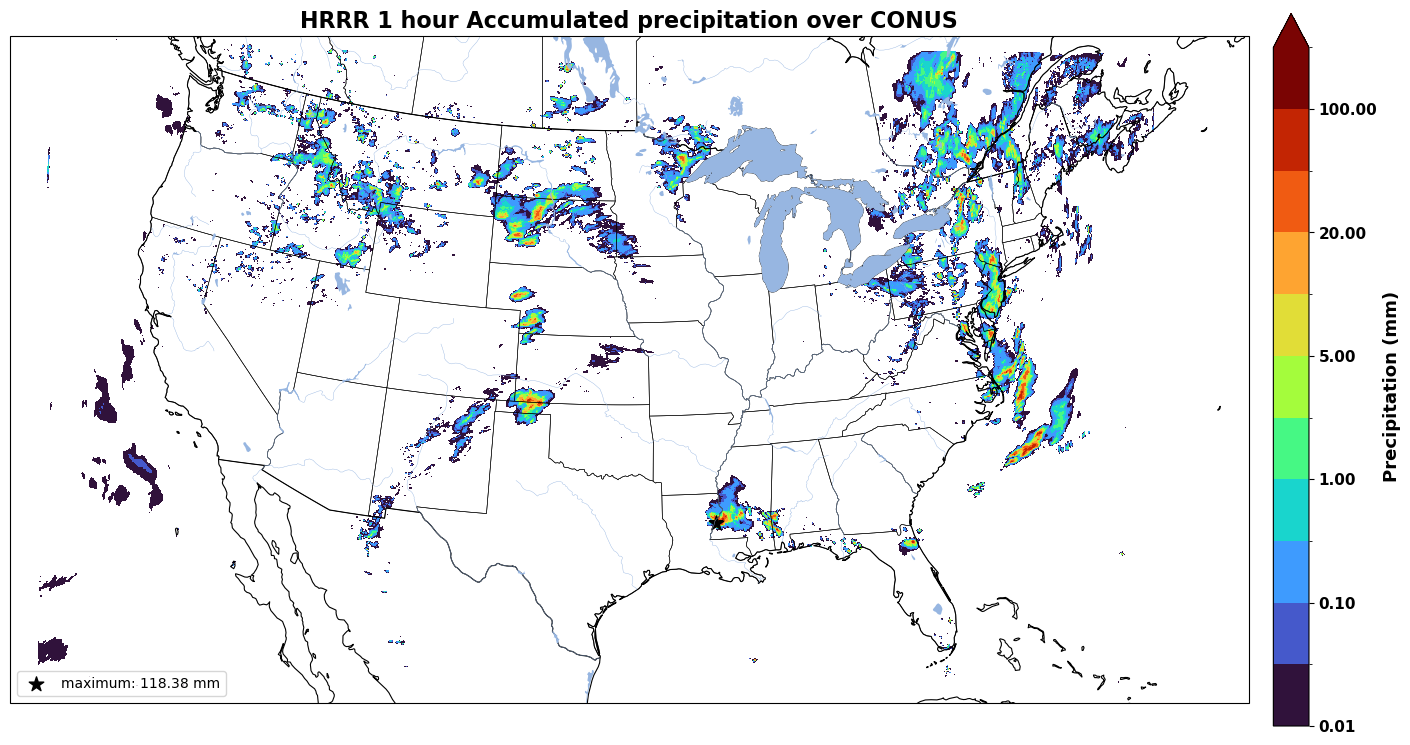

maximum APCP: 118.38 mm at (31.726, -91.326)


In [22]:

# now lets define the levels for the precipitation visualization -
precipitation_levels = [
    0.01,
    0.05,
    0.1,
    0.5,
    1,
    2,
    5,
    10,
    20,
    50,
    100,
    150,
    ]

precipitation_cmap = plt.get_cmap("turbo", len(precipitation_levels) - 1)

precipitation_norm = BoundaryNorm(precipitation_levels, precipitation_cmap.N)

# lets mask out dry pixels
wet_apcp_grid = np.ma.masked_where(apcp_grid <= 0, apcp_grid)

# lets also display the max precipitation location
# finding maximum precipitation location
maximum_flat_index = np.ma.argmax(apcp_grid)
maximum_row, maximum_column = np.unravel_index(maximum_flat_index, apcp_grid.shape)

maximum_apcp = float(apcp_grid[maximum_row, maximum_column])
maximum_latitude = float(latitudes_2d[maximum_row, maximum_column])
maximum_longitude = float(longitudes_2d[maximum_row, maximum_column])

# now we can create map
figure = plt.figure(figsize=(14, 8), constrained_layout=True)
axis = plt.axes(projection=ccrs.LambertConformal())

# set CONUS extent
axis.set_extent([-125, -66.5, 24, 50], crs=ccrs.PlateCarree())

# adding map features
axis.add_feature(cfeature.COASTLINE, linewidth=0.8)
axis.add_feature(cfeature.BORDERS, linewidth=0.8)
axis.add_feature(cfeature.STATES, linewidth=0.4)
axis.add_feature(cfeature.LAKES, linewidth=0.5)
axis.add_feature(cfeature.RIVERS, linewidth=0.3)

# precipitation overlay
image = axis.pcolormesh(
    longitudes_2d,
    latitudes_2d,
    wet_apcp_grid,
    cmap=precipitation_cmap,
    norm=precipitation_norm,
    shading="auto",
    rasterized=True,
    transform=ccrs.PlateCarree(),
    )

# mark max precipitation point
axis.scatter(
    maximum_longitude,
    maximum_latitude,
    marker="*",
    s=120,
    color="black",
    transform=ccrs.PlateCarree(),
    label=f"maximum: {maximum_apcp:.2f} mm",
    )

axis.set_title("HRRR 1 hour Accumulated precipitation over CONUS", fontsize=16, fontweight='bold')
axis.legend(loc="lower left")

colorbar = figure.colorbar(
    image,
    ax=axis,
    extend="max",
    pad=0.02,
    shrink=0.9,
    )

colorbar.set_label("Precipitation (mm)", fontsize=13, fontweight="bold")
colorbar.ax.tick_params(labelsize=11)
for tick in colorbar.ax.get_yticklabels():
    tick.set_fontweight("bold")
    
plt.show()

print(f"maximum APCP: {maximum_apcp:.2f} mm "
    f"at ({maximum_latitude:.3f}, {maximum_longitude:.3f})")


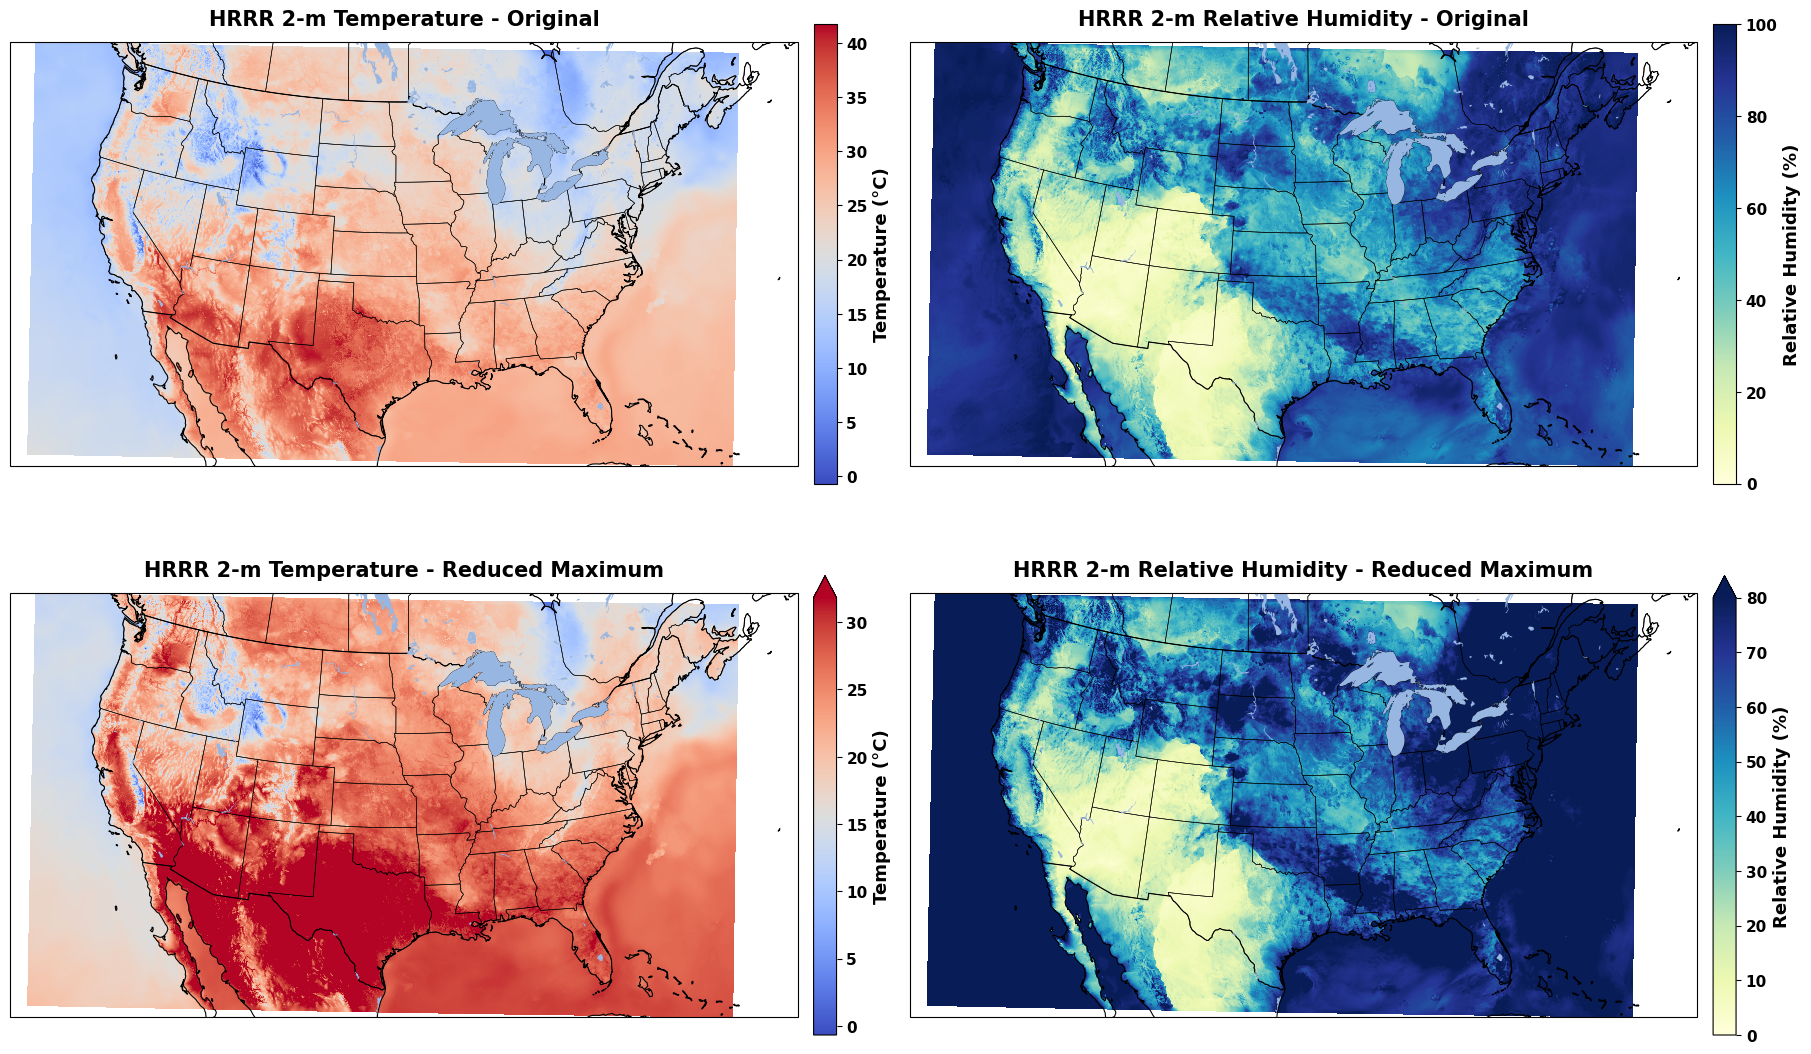

Temperature maximum: 41.70 °C
Reduced temperature maximum: 31.83 °C
Humidity maximum: 100%
Reduced humidity maximum: 80%


In [23]:

# lets also visualize the temp and relative humidity too

# setting colorbar limits
temperature_valid = np.ma.filled(np.ma.masked_invalid(temperature_grid_c), np.nan)

humidity_valid = np.ma.filled(np.ma.masked_invalid(humidity_grid_percent), np.nan)

# Cclculate statistics using valid values only
temp_min = float(np.nanmin(temperature_valid))
temp_max = float(np.nanmax(temperature_valid))
temp_max_lower = float(np.nanpercentile(temperature_valid, 90))

humidity_max = 100
humidity_max_lower = 80

# create 2 rows x 2 columns
figure, axes = plt.subplots(
    nrows=2,
    ncols=2,
    figsize=(18, 11),
    subplot_kw={"projection": ccrs.LambertConformal()},
    constrained_layout=True,
    )

# defining visualization settings
plot_settings = [
    ("Temperature - Original", temperature_grid_c,
     "coolwarm", temp_min, temp_max, "Temperature (°C)"),

    ("Relative Humidity - Original", humidity_grid_percent,
     "YlGnBu", 0, humidity_max, "Relative Humidity (%)"),

    ("Temperature - Reduced Maximum", temperature_grid_c,
     "coolwarm", temp_min, temp_max_lower, "Temperature (°C)"),

    ("Relative Humidity - Reduced Maximum", humidity_grid_percent,
     "YlGnBu", 0, humidity_max_lower, "Relative Humidity (%)"),
    ]

# now we can loop through the settings and visualize each of that
for axis, (title, data, cmap, vmin, vmax, label) in zip(
    axes.flat, plot_settings
    ):
    axis.set_extent([-125, -66.5, 24, 50], crs=ccrs.PlateCarree())

    axis.add_feature(cfeature.COASTLINE, linewidth=0.8)
    axis.add_feature(cfeature.BORDERS, linewidth=0.8)
    axis.add_feature(cfeature.STATES, linewidth=0.4)
    axis.add_feature(cfeature.LAKES, linewidth=0.5)

    image = axis.pcolormesh(
        longitudes_2d,
        latitudes_2d,
        data,
        cmap=cmap,
        vmin=vmin,
        vmax=vmax,
        shading="auto",
        rasterized=True,
        transform=ccrs.PlateCarree(),
        )

    axis.set_title(f"HRRR 2-m {title}", fontsize=15, fontweight="bold", pad=12)
    colorbar = figure.colorbar(image, ax=axis, pad=0.02,
        shrink=0.85, extend="max" if "Reduced" in title else "neither")

    colorbar.set_label(label, fontsize=13, fontweight="bold")
    colorbar.ax.tick_params(labelsize=11)
    for tick in colorbar.ax.get_yticklabels():
        tick.set_fontweight("bold")

plt.show()

print(f"Temperature maximum: {temp_max:.2f} °C")
print(f"Reduced temperature maximum: {temp_max_lower:.2f} °C")
print(f"Humidity maximum: {humidity_max}%")
print(f"Reduced humidity maximum: {humidity_max_lower}%")




The three HRRR fields have the expected CONUS coverage and geographic orientation. APCP forms organized precipitation systems rather than isolated grid noise. The maximum one hour accumulation is 118.38 mm near 31.726°N, 91.326°W. 

Temperature and relative humidity show physically coherent spatial patterns. The southwestern United States is generally warmer and drier, while the eastern, northern, coastal, and mountainous regions are cooler or more humid.


In [24]:

selected_variable_table = pd.DataFrame(
                            [
                                {
                                "field": "APCP",
                                "short_name": "tp",
                                "level": "surface",
                                "units": "mm",
                                "time_meaning": "0–1 hour accumulation",
                                "role": "HRRR precipitation forecast",
                                "decision": "keep",
                                },
                                {
                                "field": "TMP",
                                "short_name": "2t",
                                "level": "2 m above ground",
                                "units": "K",
                                "time_meaning": "instantaneous at valid time",
                                "role": "near-surface temperature",
                                "decision": "keep",
                                },
                                {
                                "field": "RH",
                                "short_name": "2r",
                                "level": "2 m above ground",
                                "units": "%",
                                "time_meaning": "instantaneous at valid time",
                                "role": "near-surface moisture",
                                "decision": "keep",
                                },
                            ]
                            )

selected_variable_table


,field,short_name,level,units,time_meaning,role,decision
0,APCP,tp,surface,mm,0–1 hour accumulation,HRRR precipitation forecast,keep
1,TMP,2t,2 m above ground,K,instantaneous at valid time,near-surface temperature,keep
2,RH,2r,2 m above ground,%,instantaneous at valid time,near-surface moisture,keep


### **Test selective downloading**

A complete HRRR surface file is approximately 155 MB, but only three records are currently needed: APCP, 2-m temperature, and 2-m relative humidity. The `.idx` file provides the byte range of each record, allowing those records to be downloaded without retrieving the complete file.

We will first selectively download the three records from the cycle for which we already have the complete file and then compare the selective copy with the original fields.

The test must confirm that the metadata, dimensions, grid definition, valid time, and numerical values match exactly. If every comparison passes, the same method can be used for other cycles.


In [25]:
fields_to_download = ["apcp", "temperature_2m", "relative_humidity_2m"]

selective_records = (selected_records[selected_records["field_name"].isin(fields_to_download)]
                    .sort_values("start_byte").reset_index(drop=True))

selective_records[
        [
        "field_name",
        "variable",
        "level",
        "time_description",
        "start_byte",
        "end_byte",
        "message_size_mb",
        ]
        ]

if len(selective_records) != 3:
    raise ValueError(f"Expected 3 selected records, found {len(selective_records)}")
    

In [26]:

# now lets download the selected byte ranges
# first lets construct the URLs
source_cycle = int(re.search(r"\.t(\d{2})z\.", sample_grib_path.name, ).group(1))

source_url = hrrr_url(download_date, source_cycle, forecast_hour)

selective_directory = day_directory / "selective_test"
selective_grib_path = (selective_directory / f"hrrr.t{source_cycle:02d}z.selected_f{forecast_hour:02d}.grib2")

selective_grib_path = download_grib_ranges(source_url, selective_records, selective_grib_path)

print("selective file size:", f"{selective_grib_path.stat().st_size / 1e6:.2f} MB")
print("complete file size:", f"{sample_grib_path.stat().st_size / 1e6:.2f} MB")


selective file size: 2.99 MB
complete file size: 154.94 MB


In [27]:

# now lets read the selective file - it contains three messages numbers as 1, 2, 3
# we assign those new numbers while preserving their field names.
selective_file_records = selective_records[["field_name"]].copy()
selective_file_records["message"] = range(1, len(selective_file_records) + 1)
selective_data = read_selected_messages(selective_grib_path, selective_file_records)

# now lets compare this with the complete file data - it should preserve the complete data since
# these bytes are coming from the same source GRIB messages

metadata_keys = [
    "name",
    "short_name",
    "units",
    "type_of_level",
    "level",
    "step_type",
    "start_step",
    "end_step",
    "initialization_date",
    "initialization_time",
    "validity_date",
    "validity_time",
    ]

grid_keys = [
    "grid_type",
    "nx",
    "ny",
    "dx_metres",
    "dy_metres",
    ]

comparison_records = []

for field_name in fields_to_download:
    original = selected_data[field_name]
    selective = selective_data[field_name]

    metadata_match = all(original["metadata"][key] == selective["metadata"][key] for key in metadata_keys)

    dimensions_match = (original["values"].shape
        == selective["values"].shape
        and original["metadata"]["nx"]
        == selective["metadata"]["nx"]
        and original["metadata"]["ny"]
        == selective["metadata"]["ny"])

    grid_match = all(original["metadata"][key] == selective["metadata"][key] for key in grid_keys)

    valid_time_match = (original["metadata"]["validity_date"]
        == selective["metadata"]["validity_date"]
        and original["metadata"]["validity_time"]
        == selective["metadata"]["validity_time"])

    values_exact_match = np.array_equal(original["values"], selective["values"], equal_nan=True)

    comparison_records.append(
                    {
                    "field": field_name,
                    "metadata_match": metadata_match,
                    "dimensions_match": dimensions_match,
                    "grid_match": grid_match,
                    "valid_time_match": valid_time_match,
                    "values_exact_match": values_exact_match,
                    }
                    )

selective_comparison = pd.DataFrame(comparison_records)
selective_comparison # it should returns all checks True


,field,metadata_match,dimensions_match,grid_match,valid_time_match,values_exact_match
0,apcp,True,True,True,True,True
1,temperature_2m,True,True,True,True,True
2,relative_humidity_2m,True,True,True,True,True


In [28]:

# just one more comparison
comparison_columns = [
    "metadata_match",
    "dimensions_match",
    "grid_match",
    "valid_time_match",
    "values_exact_match",
    ]
selective_download_passed = (selective_comparison[comparison_columns].to_numpy().all())
print("selective download validation passed:", selective_download_passed)

if not selective_download_passed:
    raise ValueError("The selective download does not exactly match "
        "the complete HRRR file.")
    

selective download validation passed: True



The selectively downloaded APCP, 2-m temperature, and 2-m relative humidity records matched the corresponding records in the complete HRRR file. Their metadata, dimensions, grid definitions, valid times, and numerical values were identical.

The byte-range download method is therefore valid for these fields. Later HRRR downloads can retrieve only the selected records rather than the complete surface files, substantially reducing storage and download requirements.


### **Temporal Consistency**

We will selectively download five cycles from the same day: 00, 06, 12, 18, and 23 UTC. These samples will test whether the selected fields, grid, units, forecast timing, and APCP accumulation definition remain consistent throughout the day.

We will also summarize how precipitation, temperature, and relative humidity change with time. These statistics describe the complete CONUS domain, regional behavior will be examined after cropping to the CBRFC area.


In [29]:
selected_variables = {
    "apcp": {
        "variable": "APCP",
        "level": "surface",
        "time_description": "0-1 hour acc fcst",
    },
    "temperature_2m": {
        "variable": "TMP",
        "level": "2 m above ground",
        "time_description": "1 hour fcst",
    },
    "relative_humidity_2m": {
        "variable": "RH",
        "level": "2 m above ground",
        "time_description": "1 hour fcst",
    },
    }

# earlier reader uses this name when checking requested fields.
selected_field_rules = selected_variables.copy()

# lets download and read multiple cycles 
temporal_cycles = [0, 6, 12, 18, 23]
temporal_directory = (day_directory / "temporal_sample")
temporal_directory.mkdir(parents=True, exist_ok=True)

temporal_samples = {}

for cycle_hour in temporal_cycles:
    print(f"processing cycle {cycle_hour:02d} UTC")
    temporal_samples[cycle_hour] = download_selected_cycle(download_date, cycle_hour, 
                                                           temporal_directory)
    

processing cycle 00 UTC
processing cycle 06 UTC
processing cycle 12 UTC
processing cycle 18 UTC
processing cycle 23 UTC


In [30]:

# lets now check metadata and calculate temporal summaries
reference_grid = {
    key: selected_data["apcp"]["metadata"][key]
    for key in [
        "grid_type",
        "nx",
        "ny",
        "dx_metres",
        "dy_metres",
        ]
        }

temporal_records = []

for cycle_hour, sample in temporal_samples.items():
    cycle_data = sample["data"]
    apcp_metadata = cycle_data["apcp"]["metadata"]
    initialization_time = grib_datetime(apcp_metadata["initialization_date"], apcp_metadata["initialization_time"])

    valid_time = grib_datetime(apcp_metadata["validity_date"], apcp_metadata["validity_time"])
    expected_initialization = datetime.strptime(f"{download_date}{cycle_hour:02d}", "%Y%m%d%H").replace(tzinfo=timezone.utc)
    expected_valid_time = (expected_initialization + timedelta(hours=forecast_hour))
    grid_match = all(apcp_metadata[key] == reference_grid[key] for key in reference_grid)

    time_match = (initialization_time == expected_initialization and valid_time == expected_valid_time)

    apcp_definition_match = (apcp_metadata["step_type"] == "accum"
                                and apcp_metadata["start_step"] == 0
                                and apcp_metadata["end_step"] == 1)

    units_match = (cycle_data["apcp"]["metadata"]["units"] == "kg m**-2"
                                and cycle_data["temperature_2m"]["metadata"]["units"] == "K"
                                and cycle_data["relative_humidity_2m"]["metadata"]["units"] == "%")

    apcp_result = get_valid_values(cycle_data["apcp"])
    temperature_result = get_valid_values(cycle_data["temperature_2m"])
    humidity_result = get_valid_values(cycle_data["relative_humidity_2m"])

    apcp_values = apcp_result["valid_values"]
    temperature_c = (temperature_result["valid_values"] - 273.15)
    humidity_percent = humidity_result["valid_values"]

    positive_apcp = apcp_values[apcp_values > 0]

    invalid_number_cells = sum(int(get_valid_values(cycle_data[field_name])["invalid_number_mask"].sum())
        for field_name in selected_variables)

    temporal_records.append(
            {
            "cycle_utc": cycle_hour,
            "initialization_time": initialization_time,
            "valid_time": valid_time,
            "grid_match": grid_match,
            "time_match": time_match,
            "apcp_definition_match": apcp_definition_match,
            "units_match": units_match,
            "invalid_number_cells": invalid_number_cells,
            "negative_apcp_cells": int(np.count_nonzero(apcp_values < 0)),
            "wet_cell_percent": (100 * positive_apcp.size / apcp_values.size),
            "median_positive_apcp_mm": (np.median(positive_apcp) if positive_apcp.size else np.nan),
            "maximum_apcp_mm": np.max(apcp_values),
            "mean_temperature_c": np.mean(temperature_c),
            "mean_relative_humidity_percent": np.mean(humidity_percent),
            }
            )


# create a df
temporal_summary = pd.DataFrame(temporal_records)
temporal_summary


,cycle_utc,initialization_time,valid_time,grid_match,time_match,apcp_definition_match,units_match,invalid_number_cells,negative_apcp_cells,wet_cell_percent,median_positive_apcp_mm,maximum_apcp_mm,mean_temperature_c,mean_relative_humidity_percent
0,0,2023-06-28 00:00:00+00:00,2023-06-28 01:00:00+00:00,True,True,True,True,0,0,8.634007,0.080,118.380,23.545875,64.267381
1,6,2023-06-28 06:00:00+00:00,2023-06-28 07:00:00+00:00,True,True,True,True,0,0,8.403525,0.030,112.120,19.397976,74.671505
2,12,2023-06-28 12:00:00+00:00,2023-06-28 13:00:00+00:00,True,True,True,True,0,0,14.872495,0.010,64.820,19.489617,75.334973
3,18,2023-06-28 18:00:00+00:00,2023-06-28 19:00:00+00:00,True,True,True,True,0,0,9.961100,0.006,40.794,25.040816,59.881027
4,23,2023-06-28 23:00:00+00:00,2023-06-29 00:00:00+00:00,True,True,True,True,0,0,6.517260,0.080,134.260,24.874326,60.905761


In [31]:

# have a simple consistency check
required_checks = [
    "grid_match",
    "time_match",
    "apcp_definition_match",
    "units_match",
    ]

temporal_consistency_passed = (temporal_summary[required_checks].to_numpy().all()
                                and temporal_summary["invalid_number_cells"].eq(0).all()
                                and temporal_summary["negative_apcp_cells"].eq(0).all())

print("temporal consistency passed:", temporal_consistency_passed)

if not temporal_consistency_passed:
    raise ValueError("At least one temporal consistency check failed.")


temporal consistency passed: True


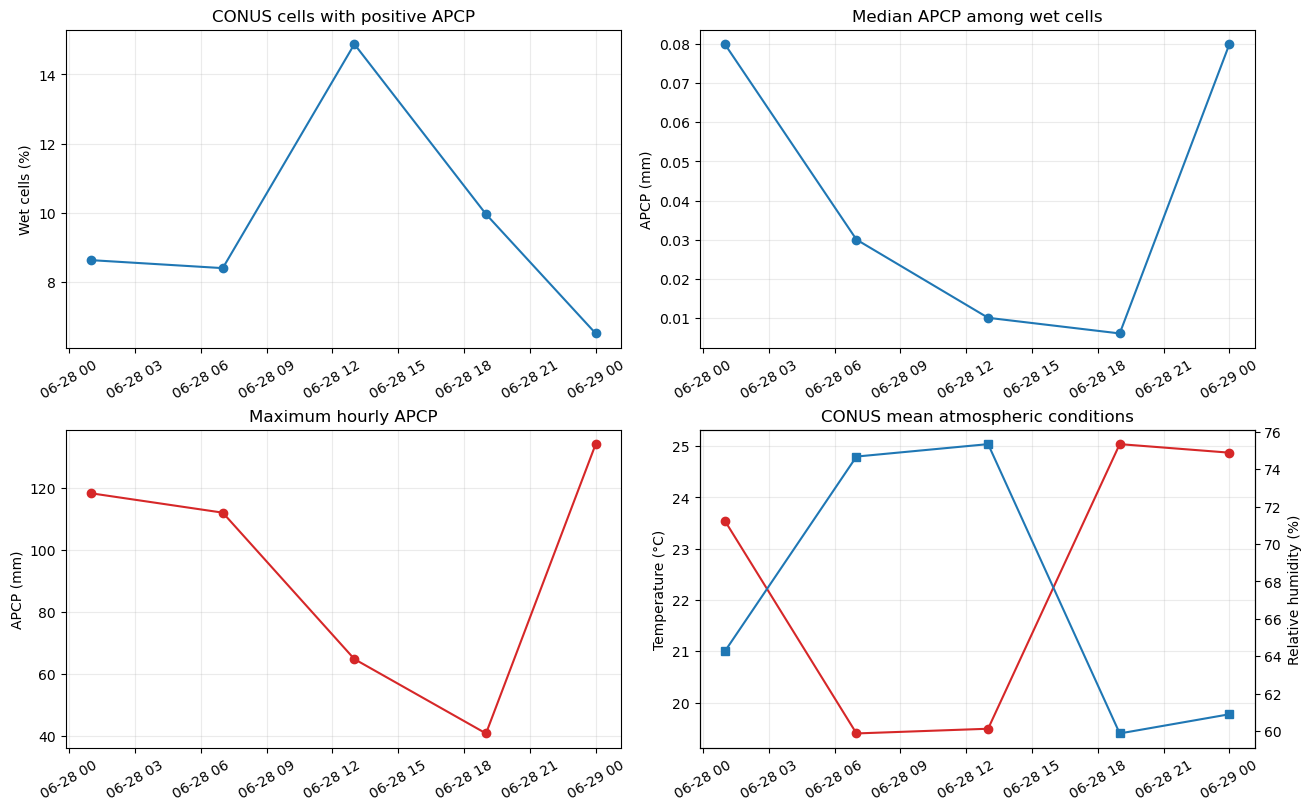

In [32]:

# lets now visualize the temporal behavior - we will see whether the selected fields change 
# smoothly and plausibly between sampled cycles
figure, axes = plt.subplots(2, 2, figsize=(13, 8), constrained_layout=True)
axes[0, 0].plot(temporal_summary["valid_time"], temporal_summary["wet_cell_percent"], marker="o")
axes[0, 0].set(title="CONUS cells with positive APCP", ylabel="Wet cells (%)")

axes[0, 1].plot(temporal_summary["valid_time"], temporal_summary["median_positive_apcp_mm"],
                        marker="o", color="tab:blue")

axes[0, 1].set(title="Median APCP among wet cells", ylabel="APCP (mm)")
axes[1, 0].plot(temporal_summary["valid_time"], temporal_summary["maximum_apcp_mm"],
                        marker="o", color="tab:red")

axes[1, 0].set(title="Maximum hourly APCP", ylabel="APCP (mm)")

temperature_axis = axes[1, 1]
temperature_axis.plot(
    temporal_summary["valid_time"],
    temporal_summary["mean_temperature_c"],
    marker="o",
    color="tab:red",
    label="Temperature")

temperature_axis.set(title="CONUS mean atmospheric conditions", ylabel="Temperature (°C)")

humidity_axis = temperature_axis.twinx()

humidity_axis.plot(
    temporal_summary["valid_time"],
    temporal_summary["mean_relative_humidity_percent"],
    marker="s",
    color="tab:blue",
    label="Relative humidity")

humidity_axis.set_ylabel("Relative humidity (%)")

for axis in axes.flat:
    axis.tick_params(axis="x", rotation=30)
    axis.grid(alpha=0.25)

plt.show()


In [33]:

# next -  we will verify the UTC day boudary - idea is that a valid-time day begins 
# with the previous date’s 23 UTC f01 cycle - without that file, the hour ending 
# at 00 UTC would be missing
previous_date = (selected_date - timedelta(days=1))
previous_date_text = previous_date.strftime("%Y%m%d")

boundary_directory = (hrrr_root / "boundary_test")
boundary_directory.mkdir( parents=True, exist_ok=True)

# now lets download the previous date UTC 23rd cycle
previous_23_sample = download_selected_cycle(previous_date_text, 23, boundary_directory)
current_00_sample = temporal_samples[0]

# compare the actual and expected valid times
boundary_samples = [previous_23_sample, current_00_sample]

boundary_records = []

for sample in boundary_samples:
    metadata = sample["data"]["apcp"]["metadata"]
    initialization_time = grib_datetime(metadata["initialization_date"], metadata["initialization_time"])
    valid_time = grib_datetime(metadata["validity_date"], metadata["validity_time"])

    expected_valid_time = (initialization_time + timedelta(hours=forecast_hour))

    boundary_records.append(
        {
        "source_date": sample["date"],
        "cycle_utc": sample["cycle"],
        "initialization_time": initialization_time,
        "actual_valid_time": valid_time,
        "expected_valid_time": expected_valid_time,
        "valid_time_match": (
            valid_time == expected_valid_time
        ),
        }
        )

boundary_summary = pd.DataFrame(boundary_records)
boundary_summary


,source_date,cycle_utc,initialization_time,actual_valid_time,expected_valid_time,valid_time_match
0,20230627,23,2023-06-27 23:00:00+00:00,2023-06-28 00:00:00+00:00,2023-06-28 00:00:00+00:00,True
1,20230628,0,2023-06-28 00:00:00+00:00,2023-06-28 01:00:00+00:00,2023-06-28 01:00:00+00:00,True


In [34]:

# lastly - confirm the exact day boundary mapping
selected_day_start = datetime.combine(selected_date, datetime.min.time(), tzinfo=timezone.utc)
expected_boundary_times = [selected_day_start, selected_day_start + timedelta(hours=1)]

day_boundary_passed = (boundary_summary["valid_time_match"].all()
                        and boundary_summary["actual_valid_time"].tolist() == expected_boundary_times)

print("UTC-day boundary check passed:", day_boundary_passed)

if not day_boundary_passed:
    raise ValueError("The HRRR UTC-day boundary mapping is incorrect.")
    

UTC-day boundary check passed: True



The five sampled HRRR cycles passed the temporal consistency checks. APCP, 2-m temperature, and 2-m relative humidity remained available with unchanged units, grid definitions, and forecast-time metadata. APCP remained a 1-hour accumulation, and no invalid or negative precipitation values were found.

The sampled fields showed plausible temporal variation. The fraction of CONUS cells with positive precipitation varied from approximately 6.5% to 15%. Positive APCP remained strongly right-skewed, and the hourly maximum varied considerably between cycles. Mean temperature and relative humidity followed an expected inverse daily pattern, with warmer sampled periods generally having lower humidity.

The UTC-day boundary test also passed. The previous day's 23 UTC `f01` cycle is valid at 00 UTC on the selected day, while the selected day's 00 UTC `f01` cycle is valid at 01 UTC. Therefore, a complete valid-time day requires the previous day's 23 UTC cycle followed by the selected day's 00-22 UTC cycles.


### **Historical consistency**

The initial analysis used a file from 2023. Before designing the complete 2021-2025 download, we need to verify that the selected HRRR fields retain the same definitions across the study period.

We will download the same calendar date and 00 UTC cycle from each year. Keeping the month, day, forecast lead, and cycle fixed makes the metadata comparison consistent.

For each year, we will compare only the information needed by the data pipeline:

- availability of the three selected fields;
- variable identity, units, and levels;
- grid definition and array size;
- APCP accumulation interval;
- initialization and valid times.

One sample per year cannot prove that every archived file is complete, but it can identify major changes in the product structure.


In [35]:

# lets select one comparable cycle for each year
historical_cycle = 0
historical_dates = {year: date(year, selected_date.month, selected_date.day).strftime("%Y%m%d")
    for year in range(2021, 2026)}

# now lets download the historical samples
historical_directory = (hrrr_root / "historical_consistency")

historical_directory.mkdir(parents=True, exist_ok=True)

historical_samples = {}

for year, date_text in historical_dates.items():
    print(f"processing {date_text}, cycle {historical_cycle:02d} UTC")
    historical_samples[year] = download_selected_cycle(date_text, historical_cycle, historical_directory)


processing 20210628, cycle 00 UTC
processing 20220628, cycle 00 UTC
processing 20230628, cycle 00 UTC
processing 20240628, cycle 00 UTC
processing 20250628, cycle 00 UTC


In [36]:

# next - verified 2023 file is our reference.
# we will test whether the same three fields in the other years have matching identities, levels,
# units, grids, and array dimensions.

reference_fields = {field_name: selected_data[field_name]["metadata"] for field_name in selected_variables}
reference_sizes = {field_name: selected_data[field_name]["values"].size for field_name in selected_variables}

grid_keys = ["grid_type",
            "nx",
            "ny",
            "dx_metres",
            "dy_metres"]

# now lets compare the years
historical_records = []

for year, sample in historical_samples.items():
    cycle_data = sample["data"]
    field_availability_match = (set(cycle_data) == set(selected_variables))

    identity_match = all(cycle_data[field_name]["metadata"]["name"] == reference_fields[field_name]["name"]
                        and cycle_data[field_name]["metadata"]["short_name"] == reference_fields[field_name]["short_name"]
                        for field_name in selected_variables)

    units_match = all(cycle_data[field_name]["metadata"]["units"] == reference_fields[field_name]["units"]
                      for field_name in selected_variables)

    levels_match = all(cycle_data[field_name]["metadata"]["type_of_level"] == reference_fields[field_name]["type_of_level"]
        and cycle_data[field_name]["metadata"]["level"] == reference_fields[field_name]["level"]
        for field_name in selected_variables)

    grid_match = all(cycle_data[field_name]["metadata"][key] == reference_fields[field_name][key]
                    for field_name in selected_variables for key in grid_keys)

    dimensions_match = all(cycle_data[field_name]["values"].size == reference_sizes[field_name]
                        for field_name in selected_variables)
    
    apcp_metadata = cycle_data["apcp"]["metadata"]
    accumulation_match = (apcp_metadata["step_type"] == "accum"
                            and apcp_metadata["start_step"] == 0 and apcp_metadata["end_step"] == 1)

    expected_initialization = datetime.strptime(
        (f"{historical_dates[year]}{historical_cycle:02d}"),
        "%Y%m%d%H").replace(tzinfo=timezone.utc)

    expected_valid_time = (expected_initialization + timedelta(hours=forecast_hour))

    time_match = all(grib_datetime(cycle_data[field_name]["metadata"]["initialization_date"], 
                    cycle_data[field_name]["metadata"]["initialization_time"]) == expected_initialization
                    and grib_datetime(cycle_data[field_name]["metadata"]["validity_date"],
                    cycle_data[field_name]["metadata"]["validity_time"]) == expected_valid_time
                    for field_name in selected_variables)

    historical_records.append(
                        {
                        "year": year,
                        "date": historical_dates[year],
                        "field_availability_match": (field_availability_match),
                        "identity_match": identity_match,
                        "units_match": units_match,
                        "levels_match": levels_match,
                        "grid_match": grid_match,
                        "dimensions_match": dimensions_match,
                        "apcp_accumulation_match": (accumulation_match),
                        "time_match": time_match,
                        }
                        )

historical_summary = pd.DataFrame(historical_records)
historical_summary


,year,date,field_availability_match,identity_match,units_match,levels_match,grid_match,dimensions_match,apcp_accumulation_match,time_match
0,2021,20210628,True,True,True,True,True,True,True,True
1,2022,20220628,True,True,True,True,True,True,True,True
2,2023,20230628,True,True,True,True,True,True,True,True
3,2024,20240628,True,True,True,True,True,True,True,True
4,2025,20250628,True,True,True,True,True,True,True,True


In [37]:

# we require all historical checks to pass - complete download should not proceed if a year uses a different 
# field definition or grid without being handled explicitly.
historical_check_columns = [
    "field_availability_match",
    "identity_match",
    "units_match",
    "levels_match",
    "grid_match",
    "dimensions_match",
    "apcp_accumulation_match",
    "time_match",
    ]

historical_consistency_passed = (historical_summary[historical_check_columns].to_numpy().all())
print("historical consistency passed:", historical_consistency_passed)

if not historical_consistency_passed:
    failed_checks = historical_summary.loc[~historical_summary[historical_check_columns].all(axis=1)]
    display(failed_checks)
    raise ValueError("At least one historical HRRR consistency check failed.")
    

historical consistency passed: True


###  **Compare the HRRR and MRMS grids**

```This step requires a corresponding MRMS file. Make sure to download those before diving into this step.```

The MRMS directory contains one rolling one hour precipitation estimate every two minutes. For alignment with the HRRR cycle initialized at 00 UTC and valid at 01 UTC, we will use the MRMS file ending exactly at 01:00 UTC.

The two products use different grids. HRRR uses an approximately 3-km Lambert conformal grid, while MRMS uses a finer regular latitude longitude grid. Before transforming HRRR fields, we must compare their times, dimensions, coordinate systems, spatial coverage, spacing, and array orientation.


In [38]:

# first lets get the file ending at 01:00
mrms_matches = sorted(mrms_pth.glob("*20230628-010000*")) # this should return only a single file

print("MRMS Matching files:", len(mrms_matches))
for path in mrms_matches:
    print(path.name)
    

MRMS Matching files: 1
MRMS_RadarOnly_QPE_01H_00.00_20230628-010000.grib2


In [39]:

mrms_file = mrms_matches[0]
mrms_metadata = read_mrms_metadata(mrms_file)
pd.Series(mrms_metadata, name="value")



name                           unknown
short_name                     unknown
units                          unknown
type_of_level           heightAboveSea
level                                0
step_type                      instant
start_step                          0m
end_step                            0m
data_date                     20230628
data_time                          100
validity_date                 20230628
validity_time                      100
grid_type                   regular_ll
nx                                7000
ny                                3500
longitude_first                230.005
longitude_last              299.994998
latitude_first                  54.995
latitude_last                20.005001
longitude_increment               0.01
latitude_increment                0.01
i_scans_negatively                   0
j_scans_positively                   0
j_points_consecutive                 0
bitmap_present                       0
missing_value            

In [40]:

# next - verify the temporal alignment - MRMS filename, header time, and HRRR valid time should all identify 01:00 UTC
# this will confirm that both products end at the same time.

mrms_time_match = re.search(r"(\d{8})-(\d{6})", mrms_file.name)

if mrms_time_match is None:
    raise ValueError("The MRMS endpoint could not be parsed from the filename.")

mrms_endpoint_time = datetime.strptime("".join(mrms_time_match.groups()), 
                                       "%Y%m%d%H%M%S").replace(tzinfo=timezone.utc)

mrms_header_time = grib_datetime(mrms_metadata["validity_date"], mrms_metadata["validity_time"])
hrrr_metadata = selected_data["apcp"]["metadata"]

hrrr_initialization_time = grib_datetime(hrrr_metadata["initialization_date"], hrrr_metadata["initialization_time"])
hrrr_valid_time = grib_datetime(hrrr_metadata["validity_date"], hrrr_metadata["validity_time"])

time_alignment = pd.Series(
                    {
                    "HRRR initialization": hrrr_initialization_time,
                    "HRRR valid time": hrrr_valid_time,
                    "MRMS filename endpoint": mrms_endpoint_time,
                    "MRMS header time": mrms_header_time,
                    "HRRR and MRMS endpoint match": (hrrr_valid_time == mrms_endpoint_time),
                    "MRMS filename and header match": (mrms_endpoint_time == mrms_header_time),
                    },
                    name="value",
                    )

time_alignment # both above checks shoudl return True


HRRR initialization               2023-06-28 00:00:00+00:00
HRRR valid time                   2023-06-28 01:00:00+00:00
MRMS filename endpoint            2023-06-28 01:00:00+00:00
MRMS header time                  2023-06-28 01:00:00+00:00
HRRR and MRMS endpoint match                           True
MRMS filename and header match                         True
Name: value, dtype: object

In [41]:

# building the MRMS coordinate axes - MRMS is a regular grid so its coordinates can be 
# reconstructed from the first cell center, grid spacing, dimensions and scan directions.

mrms_nx = int(mrms_metadata["nx"])
mrms_ny = int(mrms_metadata["ny"])

longitude_step = float(mrms_metadata["longitude_increment"])
latitude_step = float(mrms_metadata["latitude_increment"])

if mrms_metadata["i_scans_negatively"] == 1:
    longitude_step *= -1

if mrms_metadata["j_scans_positively"] == 0:
    latitude_step *= -1

mrms_longitudes = (float(mrms_metadata["longitude_first"]) + np.arange(mrms_nx) * longitude_step)
mrms_latitudes = (float(mrms_metadata["latitude_first"]) + np.arange(mrms_ny) * latitude_step)

# converting the longs from 0-360 to -180-180
mrms_longitudes = np.where(mrms_longitudes > 180, mrms_longitudes - 360, mrms_longitudes)


# now let confrim the constructed points
coordinate_check = pd.Series(
                    {
                    "shape": (mrms_ny, mrms_nx),
                    "calculated_last_longitude": (mrms_longitudes[-1]),
                    "metadata_last_longitude": (float(mrms_metadata["longitude_last"]) - 360),
                    "calculated_last_latitude": (mrms_latitudes[-1]),
                    "metadata_last_latitude": float(mrms_metadata["latitude_last"]),
                    "longitude_direction": ("eastward" if mrms_longitudes[-1] > mrms_longitudes[0] 
                                            else "westward"),
                    "latitude_direction": ("northward" if mrms_latitudes[-1]  > mrms_latitudes[0]
                                            else "southward"),
                    },
                    name="value",
                    )

coordinate_check


shape                        (3500, 7000)
calculated_last_longitude         -60.005
metadata_last_longitude        -60.005002
calculated_last_latitude           20.005
metadata_last_latitude          20.005001
longitude_direction              eastward
latitude_direction              southward
Name: value, dtype: object

In [42]:

# now lets compare the HRRR and MRMS grids
grid_comparison = pd.DataFrame(
                    [
                    {
                    "product": "HRRR",
                    "grid_type": hrrr_metadata["grid_type"],
                    "rows": int(hrrr_metadata["ny"]),
                    "columns": int(hrrr_metadata["nx"]),
                    "number_of_cells": (int(hrrr_metadata["ny"]) * int(hrrr_metadata["nx"])),
                    "x_spacing": hrrr_metadata["dx_metres"],
                    "y_spacing": hrrr_metadata["dy_metres"],
                    "spacing_units": "metres",
                    "minimum_longitude": float(np.nanmin(longitudes_2d)),
                    "maximum_longitude": float(np.nanmax(longitudes_2d)),
                    "minimum_latitude": float(np.nanmin(latitudes_2d)),
                    "maximum_latitude": float(np.nanmax(latitudes_2d)),
                    },
                    {
                    "product": "MRMS",
                    "grid_type": mrms_metadata["grid_type"],
                    "rows": mrms_ny,
                    "columns": mrms_nx,
                    "number_of_cells": (mrms_ny * mrms_nx),
                    "x_spacing": abs(longitude_step),
                    "y_spacing": abs(latitude_step),
                    "spacing_units": "degrees",
                    "minimum_longitude": float(mrms_longitudes.min()),
                    "maximum_longitude": float(mrms_longitudes.max()),
                    "minimum_latitude": float(mrms_latitudes.min()),
                    "maximum_latitude": float(mrms_latitudes.max()),
                    },
                    ]
                    )

grid_comparison


,product,grid_type,rows,columns,number_of_cells,x_spacing,y_spacing,spacing_units,minimum_longitude,maximum_longitude,minimum_latitude,maximum_latitude
0,HRRR,lambert,1059,1799,1905141,3000.00,3000.00,metres,-134.09548,-60.917193,21.138123,52.615653
1,MRMS,regular_ll,3500,7000,24500000,0.01,0.01,degrees,-129.99500,-60.005000,20.005000,54.995000


In [43]:

# comparing array orientation - both arrays must be interpreted with the correct row and column directions.
# therwise, a field can appear geographically flipped despite having the correct shape.
hrrr_longitude_change = np.nanmedian(longitudes_2d[:, 1:] - longitudes_2d[:, :-1])

hrrr_latitude_change = np.nanmedian(latitudes_2d[1:, :] - latitudes_2d[:-1, :])

orientation_comparison = pd.DataFrame(
                            [
                            {
                            "product": "HRRR",
                            "columns_move": ("eastward" if hrrr_longitude_change > 0 else "westward"),
                            "rows_move": ("northward" if hrrr_latitude_change > 0 else "southward"),
                            "northwest_latitude": float(latitudes_2d[0, 0]),
                            "northwest_longitude": float(longitudes_2d[0, 0]),
                            },
                            {
                            "product": "MRMS",
                            "columns_move": ("eastward" if mrms_longitudes[-1] > mrms_longitudes[0] else "westward"),
                            "rows_move": ("northward" if mrms_latitudes[-1] > mrms_latitudes[0] else "southward"),
                            "northwest_latitude": float(mrms_latitudes[0]),
                            "northwest_longitude": float( mrms_longitudes[0]),
                            },
                            ]
                            )

orientation_comparison


,product,columns_move,rows_move,northwest_latitude,northwest_longitude
0,HRRR,eastward,northward,21.138123,-122.719528
1,MRMS,eastward,southward,54.995000,-129.995000


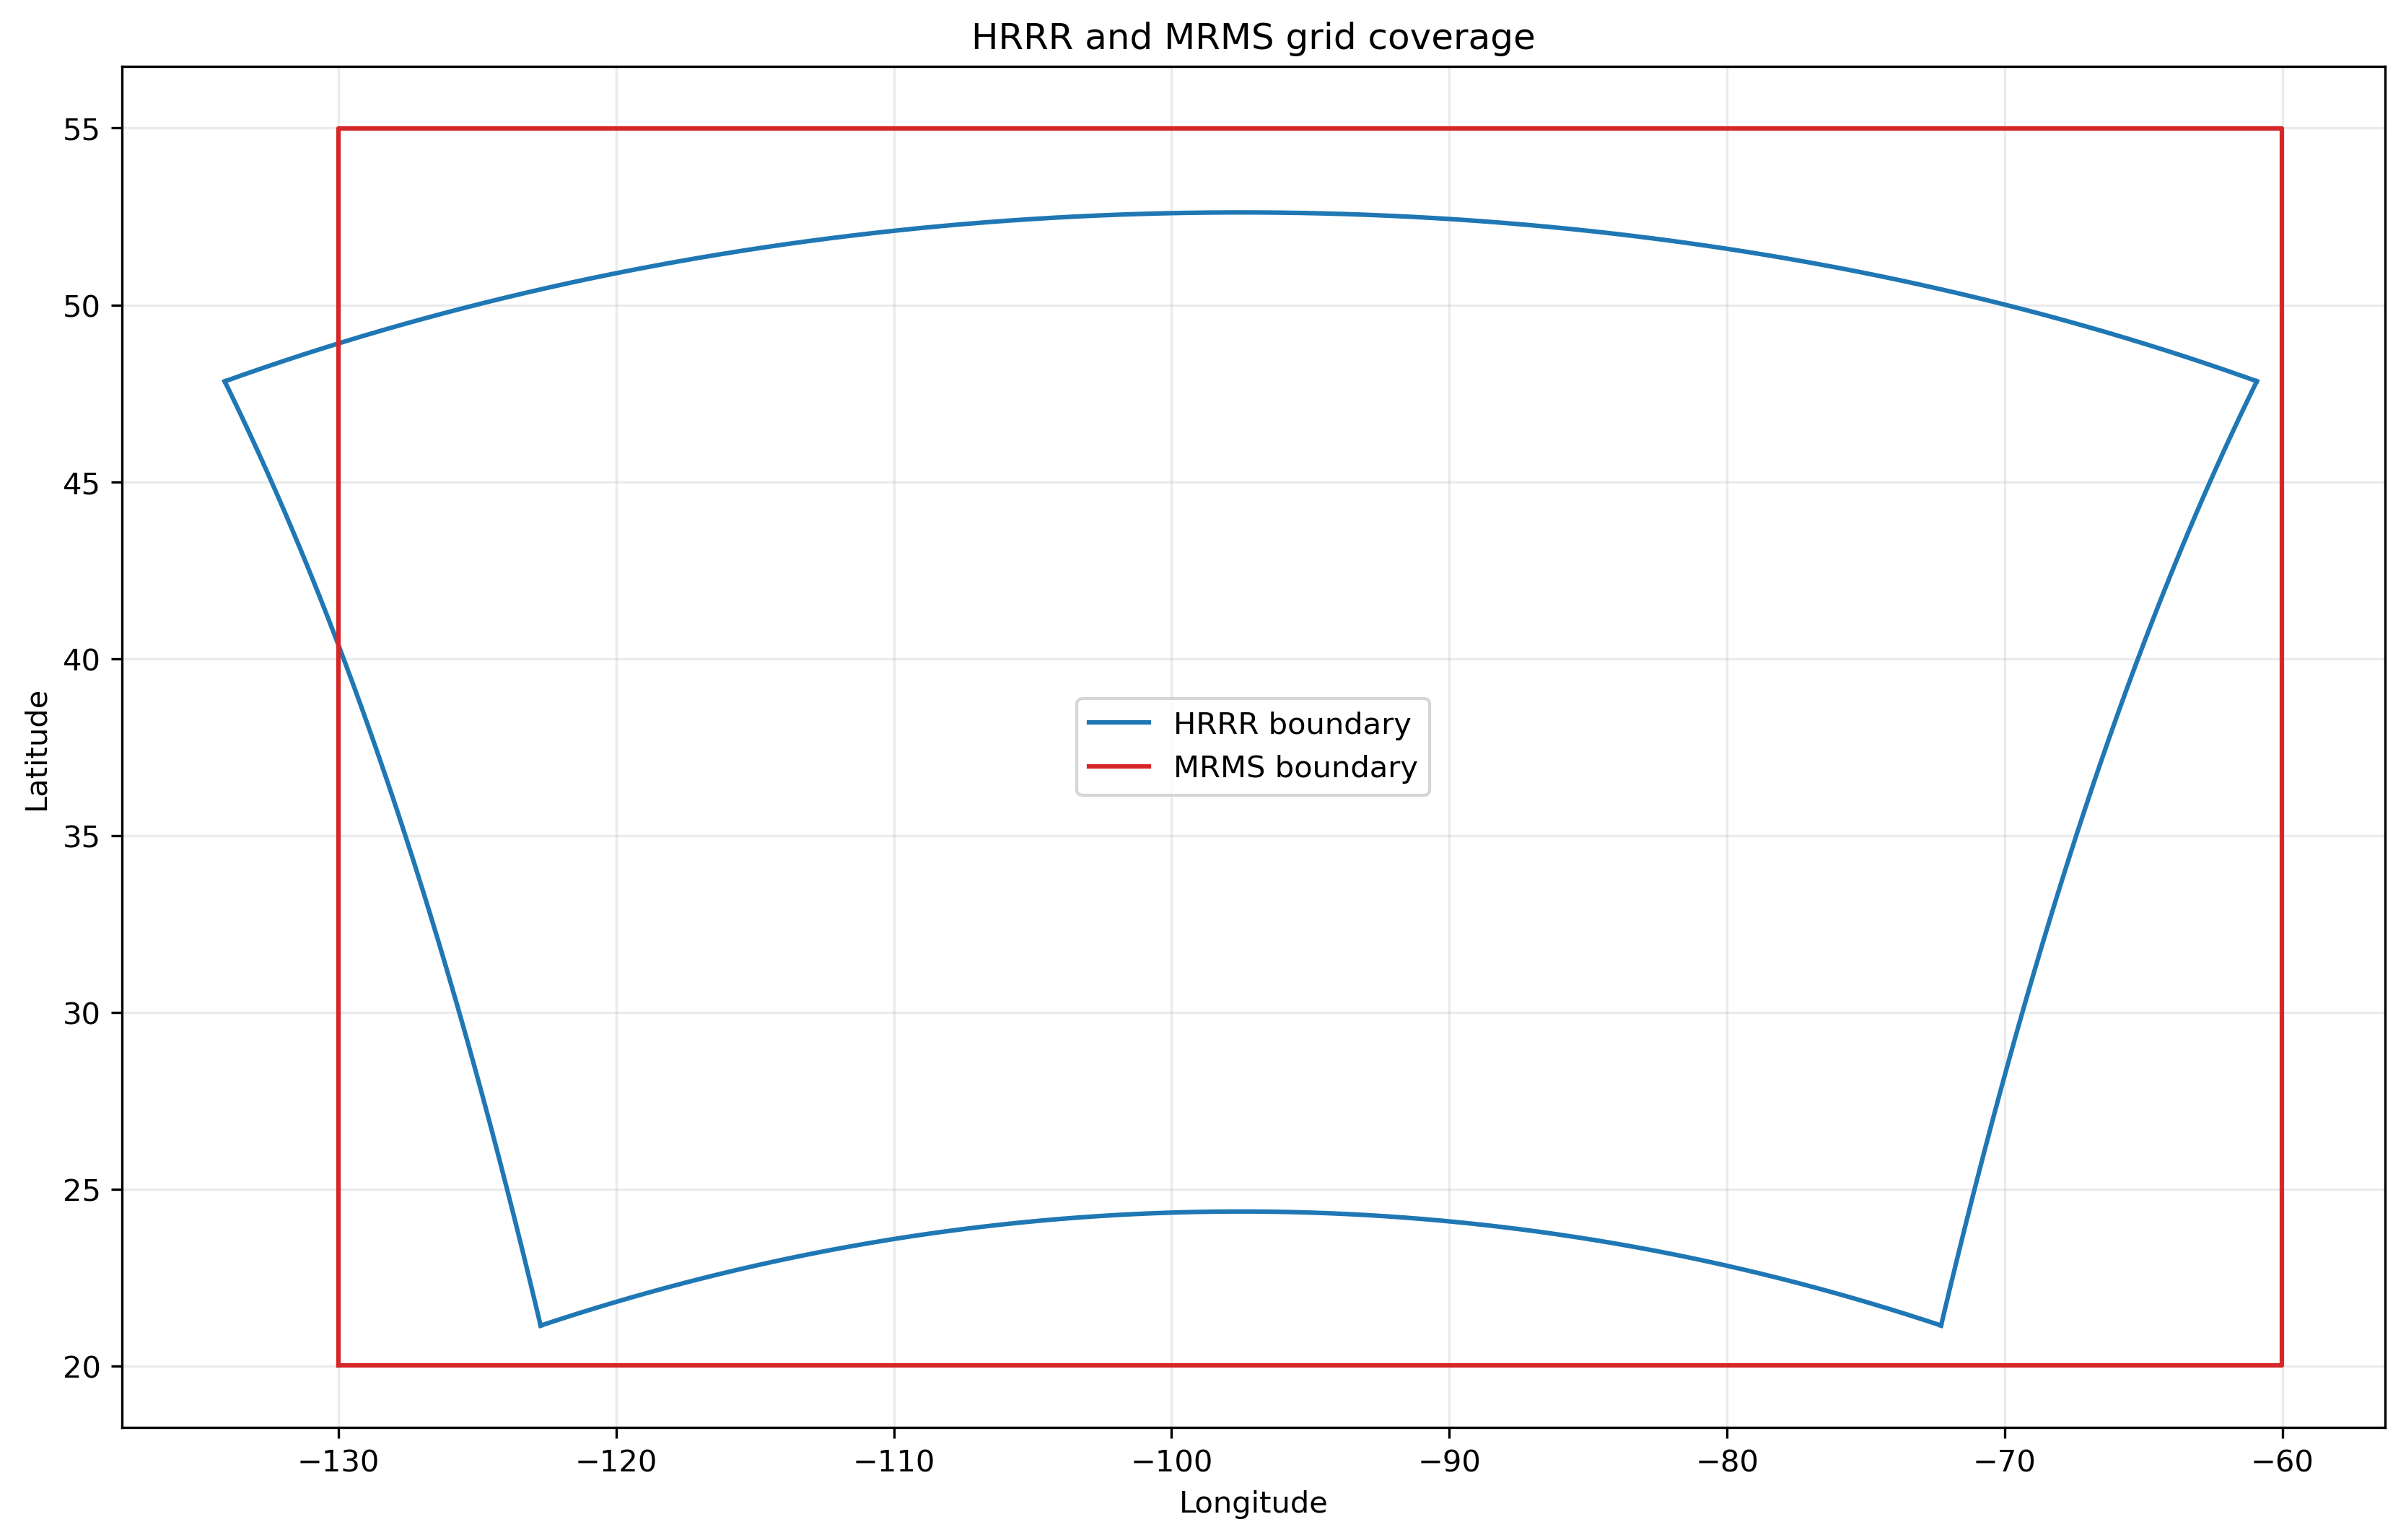

In [44]:


# now lets visualize both grids boundaries
mrms_bounds = {
    "west": float(mrms_longitudes.min()),
    "east": float(mrms_longitudes.max()),
    "south": float(mrms_latitudes.min()),
    "north": float(mrms_latitudes.max()),
    }

figure, axis = plt.subplots(figsize=(11, 7), constrained_layout=True, dpi=300)

axis.plot(longitudes_2d[0, :], latitudes_2d[0, :], color="tab:blue", label="HRRR boundary")
axis.plot(longitudes_2d[-1, :], latitudes_2d[-1, :], color="tab:blue")
axis.plot(longitudes_2d[:, 0], latitudes_2d[:, 0], color="tab:blue")
axis.plot(longitudes_2d[:, -1], latitudes_2d[:, -1], color="tab:blue")

mrms_boundary_longitudes = [mrms_bounds["west"],
                            mrms_bounds["east"],
                            mrms_bounds["east"],
                            mrms_bounds["west"],
                            mrms_bounds["west"]]

mrms_boundary_latitudes = [mrms_bounds["south"],
                            mrms_bounds["south"],
                            mrms_bounds["north"],
                            mrms_bounds["north"],
                            mrms_bounds["south"],
                            ]

axis.plot(mrms_boundary_longitudes, mrms_boundary_latitudes, color="tab:red", label="MRMS boundary")
axis.set(title="HRRR and MRMS grid coverage", xlabel="Longitude", ylabel="Latitude")

axis.grid(alpha=0.25)
axis.legend()
plt.show()



The HRRR and MRMS files have matching endpoint times. HRRR was initialized at 00:00 UTC and is valid at 01:00 UTC, while both the MRMS filename and header identify 01:00 UTC. The two products therefore represent precipitation information ending at the same time. The MRMS one-hour accumulation meaning comes from the `RadarOnly_QPE_01H` product identity because its locally defined GRIB parameter is not fully decoded by ecCodes.

The reconstructed MRMS coordinates agree with the GRIB metadata. MRMS uses a 3500 by 7000 regular latitude-longitude grid with 0.01° spacing and 24.5 million cells. Its columns move eastward and its rows move southward.

HRRR uses a 1059 × 1799 Lambert conformal grid with 3-km spacing and approximately 1.9 million cells. Its columns move eastward, but its rows move northward. Therefore, HRRR and MRMS rows have opposite orientations and cannot be matched by array indices. 

The two products have broad overlapping coverage, but neither complete domain contains the other. HRRR extends farther west in some areas, while MRMS extends farther north and slightly farther south and east. 


### **Reference and Documentation**

1. [NOAA Global Systems Laboratory: High-Resolution Rapid Refresh](https://rapidrefresh.noaa.gov/hrrr/)
2. [NOAA Environmental Modeling Center: HRRR System Description](https://emc.ncep.noaa.gov/emc/pages/numerical_forecast_systems/hrrr.php)
3. [NCEP: HRRR Product Inventory](https://www.nco.ncep.noaa.gov/pmb/products/hrrr/)
4. [NOAA HRRR Archive on AWS](https://registry.opendata.aws/noaa-hrrr-pds/)